# Major CS — estudo de previsão de confrontos

**Autor do estudo:** Roger França Peloso · **Revisão didática:** 17/11/2026

## Objetivo e estado atual

Estimar a probabilidade de uma equipe vencer um confronto de Counter-Strike e, em uma fase posterior, usar essas probabilidades para simular um Major. O modelo de referência prevê **a série completa** (MD1, MD3 ou MD5); ele ainda não prevê cada mapa separadamente.

**Concluído:** auditoria dos dados, duas remoções pontuais de duplicatas, reconstrução do alvo, históricos anteriores ao confronto, separação cronológica e treinamento/validação da V1.

**Evolução executada em 17/11/2026:** integração do ranking histórico, auditoria de mapas, comparação de versões, teste final e simulação exploratória do PGL Major Singapore 2026. As seções 1–6 conservam o registro da V1; os resultados posteriores aparecem a partir do tópico 7.

## Como usar este notebook no futuro

1. Abra o notebook na pasta `major`, com os CSVs ao lado, e selecione o ambiente Python do projeto.
2. Reinicie o kernel e execute a parte concluída de cima para baixo. Cada célula depende das tabelas produzidas nas anteriores.
3. Leia os blocos **Objetivo**, **Como interpretar** e **Decisão** antes de alterar o código.
4. As contagens e métricas registradas abaixo correspondem ao CSV revisado em 17/11/2026. Se os arquivos forem atualizados, as saídas deverão ser recalculadas.
5. As células a partir do tópico 7 leem os resultados arquivados. Elas não instalam dependências, coletam dados nem treinam modelos automaticamente. A execução completa está nos arquivos de `scripts/`. A célula 6.4 continua sendo o salvamento original da V1 e pode sobrescrevê-la se reexecutada.

## Roteiro de leitura

- [1. Ambiente e dados de entrada](#ambiente)
- [2. Granularidade, identidade das equipes e duplicatas](#auditoria)
- [3. Resultado da série e construção do alvo](#alvo)
- [4. Histórico anterior ao confronto](#historico)
- [5. Treino, validação e teste](#separacao)
- [6. Modelo V1 e interpretação das métricas](#modelo-v1)
- [7. Integração com o ranking histórico HLTV](#integracao-hltv)
- [8. Mapas e históricos anteriores ao confronto](#historico-mapas)
- [9. Experimentos, teste final e Major de Singapura](#experimentos-major)
- [10. Registro de decisões e limites](#decisoes)

> **Regra temporal:** uma variável de entrada deve representar uma informação disponível no momento em que a previsão seria feita. Um resultado posterior pode servir para calcular o alvo ou o histórico de um confronto futuro, mas não para prever o próprio confronto que produziu esse resultado.

<a id="ambiente"></a>
## 1. Ambiente e dados de entrada

### 1.1 Importações e verificação do ambiente

**Objetivo:** carregar as bibliotecas de tratamento, visualização, treinamento e avaliação.

`sys.executable` mostra qual Python está executando o notebook. Esse caminho precisa corresponder ao ambiente do projeto. A versão do scikit-learn é exibida para facilitar a reprodução futura.

In [199]:
# Tratamento e visualização de dados
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

# Treinamento
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Referência e avaliação
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

print("scikit-learn:", sklearn.__version__)
print("Python:", sys.executable)

scikit-learn: 1.9.1
Python: c:\Users\roger.peloso\Desktop\major\.venv\Scripts\python.exe


### 1.2 Configuração de exibição

As configurações a seguir alteram a aparência dos gráficos e tabelas. Os avisos de treinamento permanecem visíveis: ocultar todos os avisos pode esconder problemas de convergência ou de compatibilidade.

In [200]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", 30)

### 1.3 Leitura da base de jogos

**Objetivo:** criar `df_matches`, a tabela de trabalho que inicialmente contém o CSV completo.

O caminho é relativo à pasta de execução. O arquivo revisado possui **13.044 linhas e 98 colunas** antes das remoções pontuais. Esta tabela mistura resultados de séries com registros dos mapas dessas séries.

In [201]:
PASTA_DADOS = Path.cwd()
caminho_jogos = PASTA_DADOS / "cs2_tier1_games.csv"

df_matches = pd.read_csv(caminho_jogos)
print("Base bruta:", df_matches.shape)
display(df_matches.head(5))

Base bruta: (13044, 98)


,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,...,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
0,7313182,-156069.0,BLAST Rivals Fall 2026,307623,Team Falcons,307624,FURIA Esports,0.0,2.0,True,3.0,NaN,NaN,NaN,NaN,...,56.2,75.6,-10.0,28.0,33.0,19.0,55.4,77.3,-5.0,47.0,28.0,12.0,109.8,79.5,19.0
1,7313182,156069.0,BLAST Rivals Fall 2026,307623,Team Falcons,307624,FURIA Esports,0.0,2.0,False,3.0,14.0,16.0,24.0,Ancient,...,56.7,73.3,-7.0,23.0,21.0,12.0,79.1,76.7,2.0,28.0,17.0,7.0,100.1,86.7,11.0
2,7313182,156070.0,BLAST Rivals Fall 2026,307623,Team Falcons,307624,FURIA Esports,0.0,2.0,False,3.0,5.0,13.0,6.0,Dust2,...,55.6,77.8,-3.0,5.0,12.0,7.0,31.6,77.8,-7.0,19.0,11.0,5.0,119.4,72.2,8.0
3,7313181,-156067.0,BLAST Rivals Fall 2026,307621,Team Spirit,307622,MOUZ,2.0,0.0,True,3.0,NaN,NaN,NaN,NaN,...,51.8,62.5,-13.0,24.0,32.0,11.0,68.7,63.4,-8.0,27.0,32.0,6.0,61.8,65.4,-5.0
4,7313181,156067.0,BLAST Rivals Fall 2026,307621,Team Spirit,307622,MOUZ,2.0,0.0,False,3.0,13.0,7.0,8.0,Mirage,...,37.1,50.0,-14.0,10.0,16.0,5.0,65.8,60.0,-6.0,12.0,15.0,2.0,55.0,60.0,-3.0


### 1.4 Tipos das colunas e descrição inicial

`info()` apresenta os tipos e a quantidade de valores preenchidos. `describe()` resume as colunas numéricas. Médias de identificadores, como `match_id`, não possuem interpretação esportiva; essas estatísticas servem aqui para reconhecer a estrutura dos dados.

In [202]:
df_matches.info()
display(df_matches.describe())

<class 'pandas.DataFrame'>
RangeIndex: 13044 entries, 0 to 13043
Data columns (total 98 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   match_id               13044 non-null  int64  
 1   game_id                11614 non-null  float64
 2   tournament             13044 non-null  str    
 3   team1_id               13044 non-null  int64  
 4   team1                  13044 non-null  str    
 5   team2_id               13044 non-null  int64  
 6   team2                  13044 non-null  str    
 7   score1_match           13043 non-null  float64
 8   score2_match           13043 non-null  float64
 9   is_total               13044 non-null  bool   
 10  bestOf                 12957 non-null  float64
 11  score1_game            9529 non-null   float64
 12  score2_game            9529 non-null   float64
 13  map_id                 9506 non-null   float64
 14  map_name               9506 non-null   str    
 15  datetime     

,match_id,game_id,team1_id,team2_id,score1_match,score2_match,bestOf,score1_game,score2_game,map_id,team1_win,games_played,team1_player1_id,team1_player2_id,team1_player3_id,...,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
count,1.304400e+04,11614.000000,13044.000000,13044.000000,13043.000000,13043.000000,12957.000000,9529.000000,9529.000000,9506.000000,13043.000000,13043.000000,12678.000000,12672.000000,12650.000000,...,11245.000000,11245.000000,11245.000000,11244.000000,11244.000000,11244.000000,11244.000000,11244.000000,11244.000000,11172.000000,11172.000000,11172.000000,11172.000000,11172.000000,11172.000000
mean,4.362160e+06,45232.680902,268439.281355,268440.281355,1.247949,1.063176,2.780042,9.388183,8.861895,10.114454,0.378441,2.311125,2474.823000,3279.187658,3017.267747,...,70.611187,70.535340,-0.744064,19.292778,19.719673,6.616240,71.454776,70.675071,-0.426894,19.291890,19.743376,6.493018,71.711699,70.604010,-0.451486
std,3.095242e+06,121040.389102,21463.501533,21463.501533,0.830716,0.873889,0.763937,5.312536,5.317800,8.388060,0.485017,0.741121,4588.712195,5345.782123,3964.990726,...,17.608650,11.207754,6.998039,11.788556,10.905611,4.622733,17.850931,11.393063,7.255008,11.888605,10.929561,4.582492,17.879007,11.330307,7.232551
min,5.890420e+05,-156069.000000,232751.000000,232752.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,5.000000,1.000000,...,13.300000,21.400000,-34.000000,1.000000,1.000000,0.000000,15.600000,20.000000,-31.000000,1.000000,1.000000,0.000000,17.800000,21.400000,-34.000000
25%,1.551378e+06,-118853.250000,251448.000000,251449.000000,1.000000,0.000000,3.000000,6.000000,5.000000,4.000000,0.000000,2.000000,416.000000,550.000000,696.000000,...,58.700000,63.600000,-5.000000,12.000000,13.000000,3.000000,59.600000,63.600000,-5.000000,11.000000,13.000000,3.000000,59.600000,63.600000,-5.000000
50%,3.099262e+06,119364.500000,267324.000000,267325.000000,1.000000,1.000000,3.000000,12.000000,10.000000,6.000000,0.000000,2.000000,1003.000000,1757.000000,2063.000000,...,69.700000,70.800000,-1.000000,16.000000,16.000000,6.000000,70.850000,71.400000,-1.000000,16.000000,16.000000,5.000000,71.000000,71.100000,-1.000000
75%,7.302479e+06,124280.750000,286976.000000,286977.000000,2.000000,2.000000,3.000000,13.000000,13.000000,23.000000,1.000000,3.000000,3020.000000,3324.250000,3760.000000,...,81.500000,78.300000,4.000000,23.000000,23.000000,8.000000,82.300000,78.300000,4.000000,23.000000,23.000000,8.000000,82.825000,78.300000,4.000000
max,1.010048e+07,156070.000000,307749.000000,307750.000000,3.000000,3.000000,5.000000,37.000000,34.000000,24.000000,1.000000,5.000000,29604.000000,29567.000000,28316.000000,...,160.000000,100.000000,34.000000,99.000000,89.000000,41.000000,161.100000,100.000000,44.000000,98.000000,91.000000,43.000000,174.900000,100.000000,39.000000


### 1.5 Valores ausentes

**Objetivo:** localizar colunas incompletas antes de escolher o tratamento.

`isna().sum()` conta ausências por coluna. A divisão por `len(df_matches)` transforma essa contagem em percentual de linhas.

**Decisão:** não preencher toda a base de uma vez. A ausência de mapa em um resultado consolidado pode decorrer da granularidade; já uma ausência em uma entrada do modelo exige tratamento próprio. A imputação das entradas será aprendida somente no treino.

,Coluna,Missing_Count,Missing_Percentage
13,map_id,3538,27.12
14,map_name,3538,27.12
12,score2_game,3515,26.95
11,score1_game,3515,26.95
96,team2_player5_kast,1872,14.35
...,...,...,...
10,bestOf,87,0.67
7,score1_match,1,0.01
8,score2_match,1,0.01
16,team1_win,1,0.01


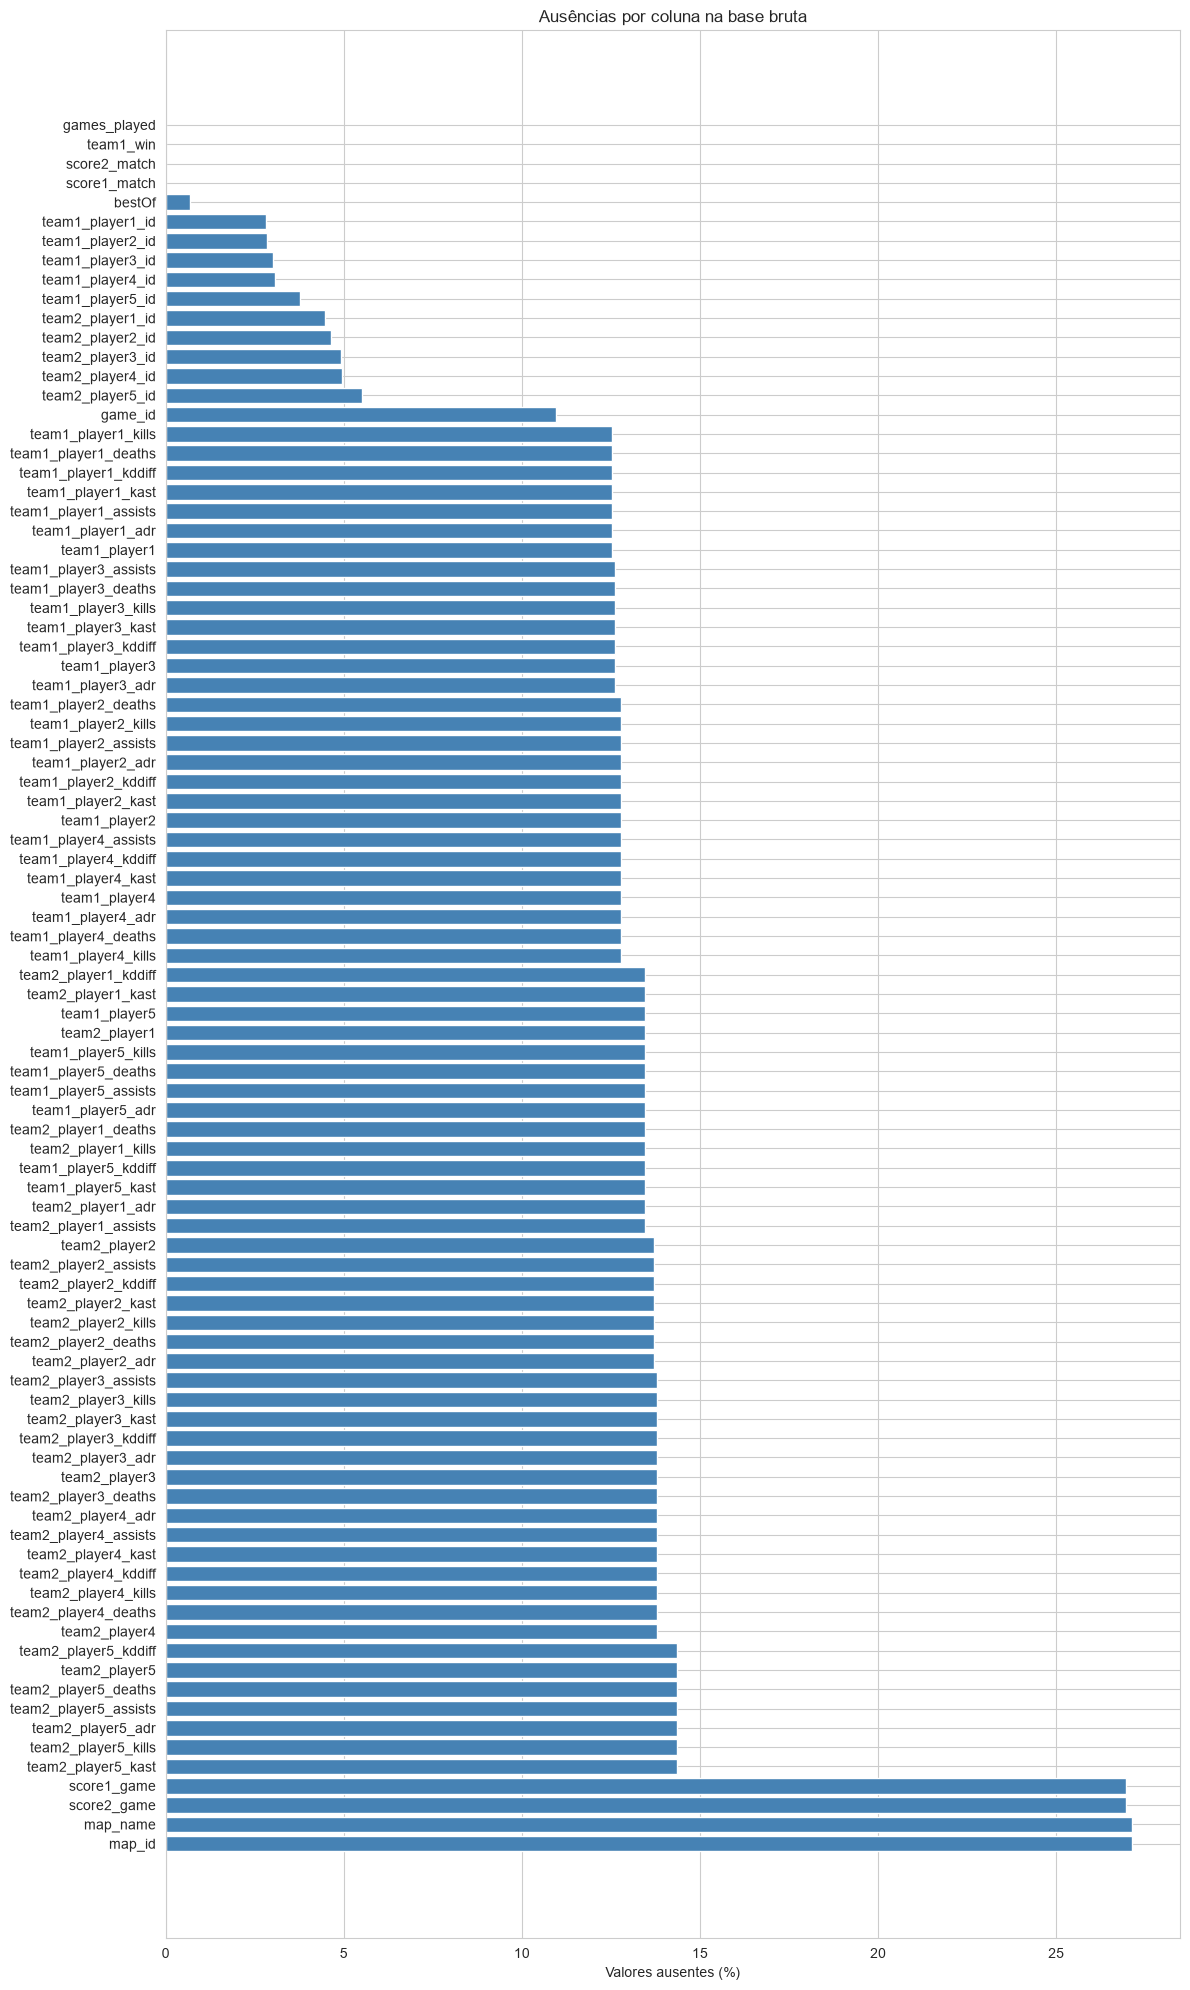

In [203]:
missing_values = pd.DataFrame({
    "Coluna": df_matches.columns,
    "Missing_Count": df_matches.isna().sum().to_numpy(),
    "Missing_Percentage": (
        df_matches.isna().sum().to_numpy() / len(df_matches) * 100
    ).round(2),
})

missing_values = missing_values.loc[
    missing_values["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

if not missing_values.empty:
    display(missing_values)
    plt.figure(figsize=(12, 20))
    plt.barh(
        missing_values["Coluna"],
        missing_values["Missing_Percentage"],
        color="steelblue",
    )
    plt.xlabel("Valores ausentes (%)")
    plt.title("Ausências por coluna na base bruta")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum valor ausente.")

<a id="auditoria"></a>
## 2. Granularidade, identidade das equipes e duplicatas


### 2.1 Série completa versus mapa individual

| Campo | Interpretação usada neste estudo |
|---|---|
| `match_id` | Identifica o confronto, incluindo todos os mapas da mesma série. |
| `is_total = True` | Linha do resultado consolidado da série. |
| `is_total = False` | Linha de um mapa individual da série. |
| `game_id` | Identificador do registro de jogo; verificar sua unicidade antes de cruzar fontes. |
| `score1_match` e `score2_match` | Mapas vencidos por cada equipe no confronto. |
| `score1_game` e `score2_game` | Rounds vencidos por cada equipe em um mapa. |
| `bestOf` | Formato previsto do confronto, por exemplo MD1, MD3 ou MD5. |

**Decisão:** a V1 terá uma linha por confronto. Os mapas serão mantidos como outra fonte de histórico. Agrupar mapas e totais indiscriminadamente contaria o mesmo confronto várias vezes.

O exemplo abaixo permite enxergar o mesmo `match_id` no total e nos mapas.

In [204]:
display(df_matches["is_total"].value_counts())
display(
    df_matches.loc[df_matches["map_name"].isna()]
    .groupby("is_total")
    .size()
)

partida = 7306663
colunas = [
    "match_id", "game_id", "is_total", "bestOf", "map_name",
    "score1_match", "score2_match",
]
display(df_matches.loc[df_matches["match_id"] == partida, colunas])

is_total
False    7850
True     5194
Name: count, dtype: int64

is_total
False      44
True     3494
dtype: int64

,match_id,game_id,is_total,bestOf,map_name,score1_match,score2_match
601,7306663,-154992.0,True,5.0,NaN,2.0,3.0
602,7306663,154992.0,False,5.0,Cache,2.0,3.0
603,7306663,154993.0,False,5.0,Nuke,2.0,3.0
604,7306663,154994.0,False,5.0,Dust2,2.0,3.0
605,7306663,154995.0,False,5.0,Mirage,2.0,3.0
606,7306663,154996.0,False,5.0,Inferno,2.0,3.0


### 2.2 Leitura do cadastro de equipes

O arquivo `teams.csv` possui nomes e IDs, mas isso ainda não prova que os IDs sejam estáveis entre partidas. É necessário testar a identidade antes de usá-los para acumular históricos.

In [205]:
caminho_times = PASTA_DADOS / "teams.csv"
df_teams = pd.read_csv(caminho_times)

print("Cadastro de equipes:", df_teams.shape)
display(df_teams.head(5))

Cadastro de equipes: (22856, 2)


,team_id,team_name
0,232751,Team Vitality
1,232752,BetBoom Team
2,232753,FaZe Clan
3,232754,GamerLegion
4,232755,Natus Vincere


### 2.3 Um mesmo nome aparece com vários IDs

Filtramos `Team Vitality` para observar quantos registros de cadastro usam esse nome. O resultado deve ser interpretado junto com a quantidade de confrontos associada a cada ID, medida adiante.

In [206]:
time = "Team Vitality"
display(df_teams.loc[df_teams["team_name"] == time])

,team_id,team_name
0,232751,Team Vitality
164,233191,Team Vitality
570,234117,Team Vitality
580,234127,Team Vitality
884,235083,Team Vitality
...,...,...
22718,306423,Team Vitality
22738,306443,Team Vitality
22752,306839,Team Vitality
22758,306845,Team Vitality


### 2.4 Conferência das colunas de identificação

Este diagnóstico mostra os campos disponíveis em cada arquivo. Ele não transforma automaticamente o ID do CSV em ID da HLTV: são fontes diferentes até que uma correspondência seja verificada.

In [207]:
print("Colunas do cadastro:", df_teams.columns.tolist())
print("Colunas dos jogos:", df_matches.columns.tolist())

Colunas do cadastro: ['team_id', 'team_name']
Colunas dos jogos: ['match_id', 'game_id', 'tournament', 'team1_id', 'team1', 'team2_id', 'team2', 'score1_match', 'score2_match', 'is_total', 'bestOf', 'score1_game', 'score2_game', 'map_id', 'map_name', 'datetime', 'team1_win', 'games_played', 'team1_player1_id', 'team1_player2_id', 'team1_player3_id', 'team1_player4_id', 'team1_player5_id', 'team2_player1_id', 'team2_player2_id', 'team2_player3_id', 'team2_player4_id', 'team2_player5_id', 'team1_player1', 'team1_player2', 'team1_player3', 'team1_player4', 'team1_player5', 'team2_player1', 'team2_player2', 'team2_player3', 'team2_player4', 'team2_player5', 'team1_player1_kills', 'team1_player1_deaths', 'team1_player1_assists', 'team1_player1_adr', 'team1_player1_kast', 'team1_player1_kddiff', 'team1_player2_kills', 'team1_player2_deaths', 'team1_player2_assists', 'team1_player2_adr', 'team1_player2_kast', 'team1_player2_kddiff', 'team1_player3_kills', 'team1_player3_deaths', 'team1_player

### 2.5 Teste de estabilidade do ID

`melt()` reúne `team1_id` e `team2_id` em uma única coluna. Depois, `nunique()` conta quantos confrontos e campeonatos cada ID representa.

**Conclusão observada:** os IDs deste conjunto se restringem a um confronto. Eles identificam a participação da equipe naquele confronto, e não fornecem uma chave estável da organização para o histórico.

In [208]:
equipes_partidas = df_matches.melt(
    id_vars=["match_id", "tournament"],
    value_vars=["team1_id", "team2_id"],
    value_name="team_id",
)

analise = equipes_partidas.groupby("team_id").agg(
    partidas=("match_id", "nunique"),
    campeonatos=("tournament", "nunique"),
)

display(analise)
display(equipes_partidas["team_id"].isin(df_teams["team_id"]).value_counts())

,partidas,campeonatos
team_id,,
232751,1,1
232752,1,1
232753,1,1
232754,1,1
232755,1,1
...,...,...
307746,1,1
307747,1,1
307748,1,1


team_id
True     25924
False      164
Name: count, dtype: int64

### 2.6 Inspeção de uma participação específica

Repetições do ID em várias linhas podem ser os mapas e o total de **um único confronto**. Por isso, `value_counts()` sozinho não demonstra que o ID acompanha a equipe ao longo do tempo.

In [209]:
codigo1 = 306849
print("Ocorrências nos dois lados:")
display(df_matches["team1_id"].value_counts())
display(df_matches["team2_id"].value_counts())
display(df_matches.loc[df_matches["team1_id"] == codigo1])

Ocorrências nos dois lados:


team1_id
306849    6
302814    6
289672    6
279928    6
260088    6
         ..
232753    1
232751    1
232755    1
232757    1
236385    1
Name: count, Length: 5192, dtype: int64

team2_id
306850    6
302815    6
289673    6
279929    6
260089    6
         ..
232754    1
232752    1
232756    1
232758    1
236386    1
Name: count, Length: 5192, dtype: int64

,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,...,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
178,7312556,-155921.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,True,5.0,NaN,NaN,NaN,NaN,...,60.3,67.8,-20.0,58.0,74.0,15.0,71.2,59.7,-16.0,67.0,54.0,18.0,69.7,71.9,13.0
179,7312556,155921.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,False,5.0,2.0,13.0,24.0,Ancient,...,59.9,80.0,-2.0,17.0,10.0,2.0,98.8,80.0,7.0,9.0,4.0,6.0,59.9,80.0,5.0
180,7312556,155922.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,False,5.0,13.0,5.0,6.0,Dust2,...,63.2,61.1,-4.0,9.0,17.0,1.0,61.9,50.0,-8.0,19.0,9.0,2.0,102.3,77.8,10.0
181,7312556,155923.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,False,5.0,13.0,2.0,1.0,Cache,...,52.7,53.3,-8.0,5.0,15.0,2.0,49.9,40.0,-10.0,7.0,13.0,4.0,48.7,66.7,-6.0
182,7312556,155925.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,False,5.0,11.0,13.0,8.0,Mirage,...,40.7,70.8,-7.0,20.0,16.0,4.0,86.0,70.8,4.0,19.0,14.0,3.0,72.2,66.7,5.0
183,7312556,155927.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,False,5.0,13.0,6.0,2.0,Nuke,...,85.2,73.7,1.0,7.0,16.0,6.0,59.5,57.9,-9.0,13.0,14.0,3.0,65.3,68.4,-1.0


### 2.7 Nomes disponíveis na base

Os nomes dos dois lados são reunidos para listar as equipes. Nesta fase, o nome exato será a chave provisória do histórico; ele não será usado diretamente como entrada numérica da regressão.

In [210]:
times = sorted(pd.concat([df_matches["team1"], df_matches["team2"]]).unique())
print("Quantidade de nomes distintos:", len(times))
display(times)

Quantidade de nomes distintos: 587


['-72C',
 '00Nation',
 '100 Thieves',
 '15 Average Gaming',
 '1ADL',
 '1w Team',
 '1win Team',
 '2ez Gaming',
 '500',
 '5star eSports',
 '6666 Esports',
 '9INE',
 '9Pandas',
 '9z Academy',
 '9z Team',
 'ABT Esports',
 'ACROBATS',
 'ALGO Esports',
 'ALTERNATE aTTaX',
 'AM Gaming',
 'AMKAL Esports',
 'ANTYKONFIDENT',
 'ARCRED',
 'ARROW',
 'ASTRAL Esports',
 'ATOX Esports',
 'ATRIVM',
 'AURA',
 'AVANGAR',
 'AY4S',
 'Acend',
 'AgencilUSB',
 'Akimbo Esports',
 'Al-Ittihad',
 'Alliance',
 'Aloha',
 'Alter Ego',
 'Anonymo Esports',
 'Aogiri',
 'Apeks',
 'Apogee Esports',
 'Arcade Esports',
 'Astralis',
 'Aurora Gaming',
 'Aurora Young Blood',
 'B8 Esports',
 'BAKS Esports',
 'BASEMENT BOYS',
 'BBL Esports',
 'BCGame',
 'BESTIA',
 'BET-M 33',
 'BETBOOM TEAM',
 'BEZFORMbI',
 'BIG',
 'BIG Academy',
 'BLAST Dream Team',
 'BLESSED',
 'BLUDS',
 'BLUEJAYS',
 'BOSS',
 'BRUTE',
 'BULGARIAPEEK',
 'Back to Back',
 'Bad News Bricks',
 'Bad News Kangaroos',
 'Badass Gaming',
 'Baltimore',
 'BenchedHeroes'

### 2.8 Nomes semelhantes: `1win Team` e `1w Team`

**Objetivo:** inspecionar ausências nos nomes e os períodos de atividade de nomes parecidos.

Datas próximas ou grafias semelhantes são indícios para investigar, mas não bastam para estabelecer continuidade da organização.

In [211]:
print("Ausências nos nomes:")
display(df_matches[["team1", "team2"]].isna().sum())

nomes = ["1win Team", "1w Team"]
for nome in nomes:
    partidas_nome = df_matches.loc[
        (df_matches["team1"] == nome) | (df_matches["team2"] == nome)
    ]
    datas = pd.to_datetime(partidas_nome["datetime"])
    print(nome, "| primeira:", datas.min(), "| última:", datas.max())

Ausências nos nomes:


team1    0
team2    0
dtype: int64

1win Team | primeira: 2024-04-08 16:00:00 | última: 2026-01-17 20:00:00
1w Team | primeira: 2026-05-28 18:00:00 | última: 2026-10-09 11:30:00


### 2.9 Escalações nas bordas dos períodos

Comparamos as escalações da última ocorrência do nome mais antigo com a primeira do mais recente. Isso ajuda a investigar uma possível mudança, mas escalação diferente não prova que se trata de outra organização, e escalação igual não resolve todos os casos de identidade.

In [212]:
nomes = ["1win Team", "1w Team"]

def partidas(nome):
    return df_matches.loc[
        (df_matches["team1"] == nome) | (df_matches["team2"] == nome)
    ]

antigo, recente = sorted(
    nomes,
    key=lambda nome: pd.to_datetime(partidas(nome)["datetime"]).min(),
)

ultima = partidas(antigo).sort_values("datetime").iloc[-1]
primeira = partidas(recente).sort_values("datetime").iloc[0]
colunas = [
    "team1_player1", "team1_player2", "team1_player3",
    "team1_player4", "team1_player5", "team2_player1",
    "team2_player2", "team2_player3", "team2_player4", "team2_player5",
]

display(df_matches.loc[df_matches["match_id"] == ultima["match_id"], colunas])
display(df_matches.loc[df_matches["match_id"] == primeira["match_id"], colunas])

,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5
3700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5
2196,"qikert (Alexey Golubev), KZ","reyozdead, RU","latt1kk (Vladislav Vydrin), RU","Oz1k, RU",cronuss,"k1to (Nils Gruhne), DE","Altekz (Alexander Givskov), DK","L00m1 (Lucas Haukland), SE","myltsi (Ville Vilkman), FI","mAriX (Max Kugener), LU"
2197,"qikert (Alexey Golubev), KZ","reyozdead, RU","latt1kk (Vladislav Vydrin), RU","Oz1k, RU",cronuss,"k1to (Nils Gruhne), DE","Altekz (Alexander Givskov), DK","L00m1 (Lucas Haukland), SE","myltsi (Ville Vilkman), FI","mAriX (Max Kugener), LU"


### 2.10 Decisão provisória sobre os nomes

**Decisão:** manter `1win Team` e `1w Team` separados, pois a continuidade entre as organizações não foi confirmada. O recorte abaixo mantém a evidência da investigação.

**Limite:** o nome pode separar indevidamente uma equipe renomeada ou juntar fases muito diferentes da mesma equipe. A integração com IDs HLTV exigirá uma tabela de equivalências com fontes e períodos de validade.

In [213]:
display(
    df_matches.loc[
        (df_matches["team1"] == "1win Team")
        | (df_matches["team2"] == "1win Team"),
        colunas,
    ].head(10)
)

,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5
3700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7426,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9283,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9368,"xfl0ud (Yasin Koç), TR","LNZ (Linus Holtäng), SE","Yxngstxr (Simon Boije), SE","jottA (Samet Köklü), TR","SaMey (Dawid Stańczak), PL","neaLaN (Sanzhar Ishkakov), KZ","buster (Timur Tulepov), KZ","latt1kk (Vladislav Vydrin), RU","Ryujin (Boris Kim), UZ","HObbit (Abay Khasenov), KZ"
9369,"xfl0ud (Yasin Koç), TR","LNZ (Linus Holtäng), SE","Yxngstxr (Simon Boije), SE","jottA (Samet Köklü), TR","SaMey (Dawid Stańczak), PL","neaLaN (Sanzhar Ishkakov), KZ","buster (Timur Tulepov), KZ","latt1kk (Vladislav Vydrin), RU","Ryujin (Boris Kim), UZ","HObbit (Abay Khasenov), KZ"
9400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9681,"neaLaN (Sanzhar Ishkakov), KZ","buster (Timur Tulepov), KZ","latt1kk (Vladislav Vydrin), RU","Ryujin (Boris Kim), UZ","HObbit (Abay Khasenov), KZ","Polt (Vadim Tsyrov), RU",NaN,"FpSSS (Dmitriy Sofronov), RU","faydett (Yuri Martirosov), RU","sugaR (Amin Azimov), AZ"


### 2.11 Verificação de totais duplicados

Filtramos primeiro `is_total = True` e então contamos linhas por `match_id`. Para construir a base de confrontos, o esperado é **um resultado consolidado por ID**.

Na revisão, foram encontrados dois IDs com resultados consolidados duplicados: **7298940** e **7287899**.

In [214]:
contagem = (
    df_matches.loc[df_matches["is_total"].eq(True)]
    .groupby("match_id")
    .size()
)
display(contagem.value_counts())
display(contagem.loc[contagem > 1])

1    5190
2       2
Name: count, dtype: int64

match_id
7287899    2
7298940    2
dtype: int64

### 2.12 Inspeção de um dos confrontos duplicados

Esta célula conserva um exemplo de auditoria. Observe resultado, equipes, campeonato e presença dos registros de mapas antes de decidir qual linha é redundante.

In [215]:
display(df_matches.loc[df_matches["match_id"] == 7298940])

,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,...,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
2787,7298940,-153266.0,PGL Astana 2026. Closed European Qualifier,289666,Lavked,289667,100 Thieves,1.0,2.0,True,3.0,NaN,NaN,NaN,NaN,...,84.2,80.7,9.0,38.0,30.0,11.0,70.9,73.8,8.0,40.0,34.0,9.0,76.2,74.7,6.0
2788,7298940,-153267.0,PGL Astana 2026. Закрытая европейская квалифик...,289666,Lavked,289667,100 Thieves,1.0,2.0,True,3.0,NaN,NaN,NaN,NaN,...,84.2,80.7,9.0,38.0,30.0,11.0,70.9,73.8,8.0,40.0,34.0,9.0,76.2,74.7,6.0
2789,7298940,153266.0,PGL Astana 2026. Закрытая европейская квалифик...,289666,Lavked,289667,100 Thieves,1.0,2.0,False,3.0,1.0,13.0,2.0,Nuke,...,96.4,100.0,6.0,11.0,6.0,3.0,78.8,85.7,5.0,17.0,7.0,1.0,103.1,71.4,10.0
2790,7298940,153267.0,PGL Astana 2026. Закрытая европейская квалифик...,289666,Lavked,289667,100 Thieves,1.0,2.0,False,3.0,13.0,5.0,24.0,Ancient,...,71.3,72.2,2.0,9.0,13.0,5.0,60.8,55.6,-4.0,13.0,13.0,3.0,62.8,77.8,0.0
2791,7298940,153268.0,PGL Astana 2026. Закрытая европейская квалифик...,289666,Lavked,289667,100 Thieves,1.0,2.0,False,3.0,7.0,13.0,6.0,Dust2,...,85.0,70.0,1.0,18.0,11.0,3.0,73.0,80.0,7.0,10.0,14.0,5.0,62.8,75.0,-4.0


### 2.13 Seleção exata das duas linhas redundantes

Foi escolhida para remoção a linha consolidada com campeonato `PGL Astana 2026. Closed European Qualifier`, preservando a outra linha consolidada e os mapas relacionados ao nome alternativo do campeonato.

**Motivo da seleção restrita:** a equivalência foi validada nesses dois IDs. Isso não autoriza excluir todas as linhas com o mesmo nome de campeonato nem remover os mapas da série.

In [216]:
duplicados_confirmados = (
    df_matches["match_id"].isin([7298940, 7287899])
    & df_matches["is_total"].eq(True)
    & df_matches["tournament"].eq(
        "PGL Astana 2026. Closed European Qualifier"
    )
)
display(df_matches.loc[duplicados_confirmados])

,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,...,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
2787,7298940,-153266.0,PGL Astana 2026. Closed European Qualifier,289666,Lavked,289667,100 Thieves,1.0,2.0,True,3.0,NaN,NaN,NaN,NaN,...,84.2,80.7,9.0,38.0,30.0,11.0,70.9,73.8,8.0,40.0,34.0,9.0,76.2,74.7,6.0
2816,7287899,-153223.0,PGL Astana 2026. Closed European Qualifier,289646,K27,289647,WW Team,2.0,0.0,True,3.0,0.0,0.0,4.0,Overpass,...,54.6,56.3,-18.0,22.0,34.0,10.0,56.7,64.2,-12.0,15.0,31.0,9.0,53.6,61.6,-16.0


### 2.14 Aplicação da limpeza confirmada

Recalculamos a máscara no estado atual de `df_matches`, o que permite repetir esta célula sem desalinhamento com uma máscara antiga. O CSV original não é sobrescrito: a remoção ocorre na tabela de trabalho.

**Conferência desta revisão:** 13.044 linhas brutas → 13.042 linhas de trabalho. Permanecem 5.192 resultados consolidados, um por confronto.

In [217]:
duplicados_confirmados = (
    df_matches["match_id"].isin([7298940, 7287899])
    & df_matches["is_total"].eq(True)
    & df_matches["tournament"].eq(
        "PGL Astana 2026. Closed European Qualifier"
    )
)

print("Linhas redundantes removidas:", int(duplicados_confirmados.sum()))
df_matches = df_matches.loc[~duplicados_confirmados].copy()
print("Base após limpeza:", df_matches.shape)

Linhas redundantes removidas: 2
Base após limpeza: (13042, 98)


<a id="alvo"></a>
## 3. Resultado da série e construção do alvo


### 3.1 Base com uma linha por confronto

`df_confrontos` seleciona os totais e converte o horário para datetime. A ordenação crescente é necessária para construir históricos anteriores.

**Resultado esperado nesta base:** 5.192 linhas e 98 colunas.

In [218]:
df_confrontos = df_matches.loc[df_matches["is_total"].eq(True)].copy()
df_confrontos["datetime"] = pd.to_datetime(df_confrontos["datetime"])
df_confrontos = df_confrontos.sort_values("datetime")

print("Confrontos:", df_confrontos.shape)
display(df_confrontos[["match_id", "datetime", "team1", "team2"]].head())

Confrontos: (5192, 98)


,match_id,datetime,team1,team2
13043,10065881,2023-01-10 09:30:00,my life be like,vagrants
13042,10064067,2023-10-16 04:30:00,VERTEX,MOUZ
13041,10064066,2023-10-16 04:30:00,Natus Vincere,Apeks
13040,10064064,2023-10-16 05:30:00,Team Vitality,BetBoom Team
13039,10064065,2023-10-16 05:40:00,FaZe Clan,GamerLegion


### 3.2 Unicidade e distribuição do vencedor original

A primeira verificação deve confirmar um total por `match_id`. A distribuição de `team1_win` levanta uma suspeita de qualidade, mas uma distribuição desigual, sozinha, não prova um erro: a confirmação precisa comparar o indicador com os placares.

In [219]:
totais = df_confrontos.groupby("match_id").size()
display(pd.Series({"Um resultado por confronto": int(totais.eq(1).sum())}))
display(totais.loc[totais > 1])
display(df_confrontos["team1_win"].value_counts(dropna=False))

Um resultado por confronto    5192
dtype: int64

Series([], dtype: int64)

team1_win
0.0    4502
1.0     689
NaN       1
Name: count, dtype: int64

### 3.3 Resultado sem vencedor informado

Inspecionamos o alvo original ausente e seus placares. O confronto **10095505** não tem informação suficiente para reconstruir o vencedor a partir do resultado consolidado.

In [220]:
colunas_resultado = [
    "match_id", "datetime", "team1", "team2", "bestOf",
    "score1_match", "score2_match", "team1_win",
]
sem_vencedor = df_confrontos["team1_win"].isna()
display(df_confrontos.loc[sem_vencedor, colunas_resultado])

,match_id,datetime,team1,team2,bestOf,score1_match,score2_match,team1_win
1682,10095505,2026-07-18 21:00:00,США,Канада,3.0,NaN,NaN,NaN


### 3.4 Comparação do indicador original com os placares

Se `team1_win` indica vitória, o placar da primeira equipe deveria ser maior; se indica derrota, deveria ser menor. Empates ou placares ausentes também precisam ser tratados separadamente.

**Decisão:** nesta etapa, usar os placares consolidados como referência para reconstruir o alvo. Isso expressa a regra adotada no estudo, não uma validação externa de todos os resultados do CSV.

In [221]:
inconsistentes = (
    (
        df_confrontos["team1_win"].eq(1)
        & (df_confrontos["score1_match"] <= df_confrontos["score2_match"])
    )
    | (
        df_confrontos["team1_win"].eq(0)
        & (df_confrontos["score1_match"] >= df_confrontos["score2_match"])
    )
)

problemas_placar = (
    df_confrontos["score1_match"].eq(df_confrontos["score2_match"])
    | df_confrontos["score1_match"].isna()
    | df_confrontos["score2_match"].isna()
)

display(df_confrontos.loc[inconsistentes, colunas_resultado])
display(df_confrontos.loc[problemas_placar, colunas_resultado])

,match_id,datetime,team1,team2,bestOf,score1_match,score2_match,team1_win
13043,10065881,2023-01-10 09:30:00,my life be like,vagrants,1.0,1.0,0.0,0.0
13041,10064066,2023-10-16 04:30:00,Natus Vincere,Apeks,1.0,1.0,0.0,0.0
13038,10064068,2023-10-16 06:45:00,ENCE,Lynn Vision Gaming,1.0,1.0,0.0,0.0
13034,10064282,2023-10-16 09:30:00,Apeks,VERTEX,3.0,2.0,0.0,0.0
13032,10064283,2023-10-16 11:30:00,BetBoom Team,GamerLegion,3.0,2.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2855,7076648,2026-03-22 17:25:00,FURIA Esports,NRG Esports,3.0,2.0,1.0,0.0
2852,7101081,2026-03-22 20:40:00,The Mongolz,Team Liquid,3.0,2.0,0.0,0.0
2849,7098612,2026-03-22 23:20:00,Team Spirit,9z Team,3.0,2.0,0.0,0.0
2842,7119182,2026-03-23 16:30:00,Team Falcons,FURIA Esports,3.0,2.0,1.0,0.0


,match_id,datetime,team1,team2,bestOf,score1_match,score2_match,team1_win
2752,7298927,2026-04-04 13:00:00,NRG Esports,Team Voca,3.0,1.0,1.0,0.0
1682,10095505,2026-07-18 21:00:00,США,Канада,3.0,NaN,NaN,NaN


### 3.5 Casos inspecionados na granularidade de mapas

O confronto **7298927** possui total 1 × 1 e dois mapas com vitória da mesma equipe. Existe uma divergência na fonte. Não vamos resolver esse caso apenas por suposição: o total permanece sem alvo definido na regra atual.

O outro confronto é mantido como exemplo de comparação. `score*_match` e `score*_game` medem coisas distintas; não devem ser comparados como se fossem o mesmo placar.

In [222]:
colunas_inspecao = [
    "match_id", "game_id", "team1", "team2", "is_total", "map_name",
    "score1_match", "score2_match", "score1_game", "score2_game",
]
for confronto in [7076648, 7298927]:
    filtro_mapas = (
        df_matches["match_id"].eq(confronto)
        & df_matches["is_total"].eq(False)
    )
    display(df_matches.loc[filtro_mapas, colunas_inspecao])

,match_id,game_id,team1,team2,is_total,map_name,score1_match,score2_match,score1_game,score2_game
2856,7076648,125794.0,FURIA Esports,NRG Esports,False,Mirage,2.0,1.0,10.0,13.0
2857,7076648,125795.0,FURIA Esports,NRG Esports,False,Nuke,2.0,1.0,13.0,2.0
2858,7076648,125796.0,FURIA Esports,NRG Esports,False,Dust2,2.0,1.0,13.0,7.0


,match_id,game_id,team1,team2,is_total,map_name,score1_match,score2_match,score1_game,score2_game
2753,7298927,153316.0,NRG Esports,Team Voca,False,Mirage,1.0,1.0,13.0,4.0
2754,7298927,153430.0,NRG Esports,Team Voca,False,Inferno,1.0,1.0,13.0,3.0


### 3.6 Nova coluna de alvo, preservando o dado original

`team1_win_corrigido` começa com `pd.NA` e recebe:

- **1:** `score1_match > score2_match`;
- **0:** `score1_match < score2_match`;
- **ausente:** empate ou placar incompleto.

**Por que não converter uma comparação booleana diretamente?** Ela poderia transformar empates ou ausências em derrotas. A inicialização com `pd.NA` preserva a incerteza.

Nesta revisão: **2.892 vitórias, 2.298 derrotas e 2 casos sem alvo**. A coluna original continua disponível para auditoria.

In [223]:
df_confrontos["team1_win_corrigido"] = pd.NA

df_confrontos.loc[
    df_confrontos["score1_match"] > df_confrontos["score2_match"],
    "team1_win_corrigido",
] = 1

df_confrontos.loc[
    df_confrontos["score1_match"] < df_confrontos["score2_match"],
    "team1_win_corrigido",
] = 0

display(df_confrontos["team1_win_corrigido"].value_counts(dropna=False))

team1_win_corrigido
1       2892
0       2298
<NA>       2
Name: count, dtype: int64

### 3.7 Base de confrontos com alvo utilizável

`df_modelo` retém somente os casos em que foi possível definir o alvo. A conversão para `int64` ocorre depois dessa seleção.

**Resultado esperado:** 5.190 linhas e 99 colunas. Os dois casos excluídos da modelagem não são inventados nem corrigidos com base em conhecimento posterior.

### O que pode entrar no modelo?

| Campo ou grupo | Papel | Motivo |
|---|---|---|
| `match_id` | Chave de auditoria | Um número de identificação não mede força da equipe. |
| `datetime` | Ordenação, corte e busca de histórico | Define quais informações já estavam disponíveis. |
| `team1`, `team2` | Chaves provisórias de histórico | Permitem recuperar dados anteriores de cada lado. |
| `bestOf` | Entrada da V1 | O formato costuma ser definido antes da disputa; validar a disponibilidade na aplicação. |
| Histórico acumulado anterior | Entrada da V1 | Foi produzido a partir de confrontos anteriores. |
| `score*_match`, `score*_game`, `games_played` do confronto atual | Construção do alvo e auditoria | Dependem do que aconteceu na disputa. |
| Kills, mortes, ADR e KAST do confronto atual | Informação posterior | Não estão disponíveis para prever essa própria disputa. |
| `team1_win_corrigido` | Alvo | É o resultado que queremos prever. |

Métricas de jogadores poderiam ser agregadas **a partir do passado** em outra experiência. O problema é usar as estatísticas do próprio confronto que se deseja prever.

In [224]:
df_modelo = df_confrontos.loc[
    df_confrontos["team1_win_corrigido"].notna()
].copy()
df_modelo["team1_win_corrigido"] = df_modelo["team1_win_corrigido"].astype("int64")

print("Base com alvo definido:", df_modelo.shape)
print("Tipo do alvo:", df_modelo["team1_win_corrigido"].dtype)
display(df_modelo["team1_win_corrigido"].value_counts(dropna=False))

Base com alvo definido: (5190, 99)
Tipo do alvo: int64


team1_win_corrigido
1    2892
0    2298
Name: count, dtype: int64

<a id="historico"></a>
## 4. Histórico anterior ao confronto


### 4.1 Duas perspectivas do mesmo confronto

Construímos uma linha para cada equipe: `equipe`, `adversario` e `venceu`. Na perspectiva da segunda equipe, o resultado é `1 - team1_win_corrigido`.

**Conferências:** cada `match_id` deve ter duas linhas; a soma de `venceu` deve ser 1. Nesta revisão são **10.380 linhas de histórico** para 5.190 confrontos.

In [225]:
colunasH = ["match_id", "datetime", "team1", "team2", "team1_win_corrigido"]

df_historico_team1 = df_modelo[colunasH].copy().rename(columns={
    "team1": "equipe",
    "team2": "adversario",
    "team1_win_corrigido": "venceu",
})
df_historico_team2 = df_modelo[colunasH].copy().rename(columns={
    "team1": "adversario",
    "team2": "equipe",
    "team1_win_corrigido": "venceu",
})
df_historico_team2["venceu"] = 1 - df_historico_team2["venceu"]

df_historico = pd.concat(
    [df_historico_team1, df_historico_team2], ignore_index=True
).sort_values("datetime")

display(df_historico.groupby("match_id").size().value_counts())
display(df_historico.groupby("match_id")["venceu"].sum().value_counts())
display(df_historico.head(10))

2    5190
Name: count, dtype: int64

venceu
1    5190
Name: count, dtype: int64

,match_id,datetime,equipe,adversario,venceu
0,10065881,2023-01-10 09:30:00,my life be like,vagrants,1
5190,10065881,2023-01-10 09:30:00,vagrants,my life be like,0
5191,10064067,2023-10-16 04:30:00,MOUZ,VERTEX,1
5192,10064066,2023-10-16 04:30:00,Apeks,Natus Vincere,0
1,10064067,2023-10-16 04:30:00,VERTEX,MOUZ,0
2,10064066,2023-10-16 04:30:00,Natus Vincere,Apeks,1
3,10064064,2023-10-16 05:30:00,Team Vitality,BetBoom Team,0
5193,10064064,2023-10-16 05:30:00,BetBoom Team,Team Vitality,1
5194,10064065,2023-10-16 05:40:00,GamerLegion,FaZe Clan,1
4,10064065,2023-10-16 05:40:00,FaZe Clan,GamerLegion,0


### 4.2 Agrupar equipe e horário antes de acumular

Existem confrontos distintos da `w7m esports` registrados no mesmo horário: **21/01/2024 às 23:00**, IDs **10066738** e **802162**.

**Decisão:** tratar todos os jogos de uma equipe no mesmo horário como um bloco. Não temos evidência para decidir qual resultado já estaria disponível para o outro jogo. Ordenar arbitrariamente por `match_id` criaria uma sequência sem fundamento temporal.

`size` conta jogos no bloco; `sum` conta vitórias. A tabela possui **10.379 combinações de equipe e horário**, representando os 10.380 registros do histórico.

In [226]:
df_resumo_horarios = (
    df_historico.groupby(["equipe", "datetime"])
    .agg(
        jogos_no_horario=("match_id", "size"),
        vitorias_no_horario=("venceu", "sum"),
    )
    .reset_index()
    .sort_values(["equipe", "datetime"])
)

print("Equipe + horário:", df_resumo_horarios.shape)
print("Jogos representados:", int(df_resumo_horarios["jogos_no_horario"].sum()))
display(df_resumo_horarios.loc[
    df_resumo_horarios["equipe"].eq("w7m esports")
    & df_resumo_horarios["datetime"].eq("2024-01-21 23:00:00")
])

Equipe + horário: (10379, 4)
Jogos representados: 10380


,equipe,datetime,jogos_no_horario,vitorias_no_horario
10096,w7m esports,2024-01-21 23:00:00,2,0


### 4.3 Acumulado anterior, excluindo o bloco atual

`groupby('equipe').cumsum()` acumula os valores de cada equipe. Subtrair a contagem do bloco atual deixa somente o que ocorreu antes dele.

`taxa_vitorias_anteriores = vitorias_anteriores / jogos_anteriores`.

**Decisão:** uma equipe sem histórico tem jogos = 0, vitórias = 0 e taxa ausente (`0 / 0`). Ausência de histórico não significa taxa de vitória de 0%.

O exemplo exibido fica antes de 01/01/2026, para manter a inspeção de atributos no período de treino. O cálculo dos históricos continua sendo feito cronologicamente para toda a base.

In [227]:
df_resumo_horarios["jogos_anteriores"] = (
    df_resumo_horarios.groupby("equipe")["jogos_no_horario"].cumsum()
    - df_resumo_horarios["jogos_no_horario"]
)
df_resumo_horarios["vitorias_anteriores"] = (
    df_resumo_horarios.groupby("equipe")["vitorias_no_horario"].cumsum()
    - df_resumo_horarios["vitorias_no_horario"]
)
df_resumo_horarios["taxa_vitorias_anteriores"] = (
    df_resumo_horarios["vitorias_anteriores"]
    / df_resumo_horarios["jogos_anteriores"]
)

equipe = "Team Vitality"
display(df_resumo_horarios.loc[
    df_resumo_horarios["equipe"].eq(equipe)
    & (df_resumo_horarios["datetime"] < "2026-01-01")
].tail(5))

,equipe,datetime,jogos_no_horario,vitorias_no_horario,jogos_anteriores,vitorias_anteriores,taxa_vitorias_anteriores
8966,Team Vitality,2025-12-05 17:00:00,1,1,151,117,0.774834
8967,Team Vitality,2025-12-06 17:00:00,1,1,152,118,0.776316
8968,Team Vitality,2025-12-11 22:05:00,1,1,153,119,0.777778
8969,Team Vitality,2025-12-13 19:00:00,1,1,154,120,0.779221
8970,Team Vitality,2025-12-14 20:00:00,1,1,155,121,0.780645


### 4.4 Associar o histórico a cada lado do confronto

São criadas duas cópias dos atributos: uma com prefixo `team1_`, outra com `team2_`. A chave da junção é **nome da equipe + horário**.

- `how='left'` mantém os confrontos da tabela principal.
- `validate='many_to_one'` impede que várias linhas de histórico para a mesma chave multipliquem um confronto.
- Quantidade de jogos ausente após a junção indica falha de correspondência. Quantidade igual a zero é um histórico válido.


In [228]:
coluna_atributos = [
    "equipe", "datetime", "jogos_anteriores",
    "vitorias_anteriores", "taxa_vitorias_anteriores",
]

atributos_team1 = df_resumo_horarios[coluna_atributos].copy().rename(columns={
    "equipe": "team1",
    "jogos_anteriores": "team1_jogos_anteriores",
    "vitorias_anteriores": "team1_vitorias_anteriores",
    "taxa_vitorias_anteriores": "team1_taxa_vitorias_anteriores",
})
atributos_team2 = df_resumo_horarios[coluna_atributos].copy().rename(columns={
    "equipe": "team2",
    "jogos_anteriores": "team2_jogos_anteriores",
    "vitorias_anteriores": "team2_vitorias_anteriores",
    "taxa_vitorias_anteriores": "team2_taxa_vitorias_anteriores",
})

df_modelo_team1 = df_modelo.merge(
    atributos_team1, on=["team1", "datetime"],
    how="left", validate="many_to_one",
)
df_modelo_team2 = df_modelo_team1.merge(
    atributos_team2, on=["team2", "datetime"],
    how="left", validate="many_to_one",
)

print("Após histórico da primeira equipe:", df_modelo_team1.shape)
print("Após histórico das duas equipes:", df_modelo_team2.shape)
display(df_modelo_team2[[
    "team1_jogos_anteriores", "team2_jogos_anteriores"
]].isna().sum())

Após histórico da primeira equipe: (5190, 102)
Após histórico das duas equipes: (5190, 105)


team1_jogos_anteriores    0
team2_jogos_anteriores    0
dtype: int64

### 4.5 Diferenças entre as equipes

As três diferenças são calculadas como **team1 − team2**. Valor positivo significa que a primeira equipe possui mais jogos, mais vitórias ou maior taxa, conforme a coluna.

**Limite:** ter mais jogos ou vitórias não é equivalente a enfrentar adversários mais fortes. Essa é uma das razões para investigar ranking e desempenho por mapa.

`df_modelo_team2` reúne a base de confrontos e os históricos dos dois lados. O nome dessa tabela não indica que ela contenha somente a segunda equipe. Nesta revisão são **5.190 linhas e 108 colunas**.

In [229]:
df_modelo_team2["dif_jogos_anteriores"] = (
    df_modelo_team2["team1_jogos_anteriores"]
    - df_modelo_team2["team2_jogos_anteriores"]
)
df_modelo_team2["dif_vitorias_anteriores"] = (
    df_modelo_team2["team1_vitorias_anteriores"]
    - df_modelo_team2["team2_vitorias_anteriores"]
)
df_modelo_team2["dif_taxa_vitorias_anteriores"] = (
    df_modelo_team2["team1_taxa_vitorias_anteriores"]
    - df_modelo_team2["team2_taxa_vitorias_anteriores"]
)

colunas_diferencas = [
    "dif_jogos_anteriores", "dif_vitorias_anteriores",
    "dif_taxa_vitorias_anteriores",
]
print("Base com diferenças:", df_modelo_team2.shape)
display(df_modelo_team2[["team1", "team2"] + colunas_diferencas].head(5))
display(df_modelo_team2[colunas_diferencas].isna().sum())

Base com diferenças: (5190, 108)


,team1,team2,dif_jogos_anteriores,dif_vitorias_anteriores,dif_taxa_vitorias_anteriores
0,my life be like,vagrants,0,0,NaN
1,VERTEX,MOUZ,0,0,NaN
2,Natus Vincere,Apeks,0,0,NaN
3,Team Vitality,BetBoom Team,0,0,NaN
4,FaZe Clan,GamerLegion,0,0,NaN


dif_jogos_anteriores              0
dif_vitorias_anteriores           0
dif_taxa_vitorias_anteriores    446
dtype: int64

<a id="separacao"></a>
## 5. Treino, validação e teste


### 5.1 Separação cronológica

| Conjunto | Regra | Quantidade nesta revisão | Uso |
|---|---|---:|---|
| Treino | Antes de 01/01/2026 | 3.775 | Aprender imputação, escala e parâmetros do modelo. |
| Validação | De 01/01/2026 até antes de 01/07/2026 | 642 | Comparar atributos e escolher versões. |
| Teste | A partir de 01/07/2026 | 773 | Avaliação final depois de fixar as escolhas. |

**Decisão:** respeitar o tempo em vez de dividir aleatoriamente. O teste permanece reservado durante o desenvolvimento.

**Como o histórico é atualizado:** a avaliação atual representa previsões sucessivas ao longo do tempo. Um confronto posterior pode usar resultados de confrontos anteriores já concluídos, inclusive dentro de validação ou teste; os parâmetros do modelo continuam fixos. Para uma previsão única de todo o Major antes do início, o histórico precisará ser congelado naquela data.

**Limite dos horários:** o CSV não documenta aqui fuso nem horário de encerramento. Excluir o mesmo horário reduz uma ambiguidade conhecida, mas a disponibilidade dos resultados de jogos que se sobrepõem ainda precisa ser validada antes da aplicação real.

In [230]:
data_treino = "2026-01-01"  # Treino: datetime < data_treino
data_teste = "2026-07-01"   # Teste: datetime >= data_teste

df_treino = df_modelo_team2.loc[
    df_modelo_team2["datetime"] < data_treino
].copy()
df_validacao = df_modelo_team2.loc[
    (df_modelo_team2["datetime"] >= data_treino)
    & (df_modelo_team2["datetime"] < data_teste)
].copy()
df_teste = df_modelo_team2.loc[
    df_modelo_team2["datetime"] >= data_teste
].copy()

resumo_divisao = pd.DataFrame([
    {
        "conjunto": nome,
        "linhas": len(tabela),
        "primeiro_horario": tabela["datetime"].min(),
        "ultimo_horario": tabela["datetime"].max(),
    }
    for nome, tabela in [
        ("treino", df_treino),
        ("validacao", df_validacao),
        ("teste", df_teste),
    ]
])
display(resumo_divisao)

,conjunto,linhas,primeiro_horario,ultimo_horario
0,treino,3775,2023-01-10 09:30:00,2025-12-14 20:00:00
1,validacao,642,2026-01-13 14:00:00,2026-06-21 18:00:00
2,teste,773,2026-07-01 11:45:00,2026-11-14 13:30:00


### 5.2 Entradas e alvo da V1

| Entrada | O que representa |
|---|---|
| `dif_jogos_anteriores` | Diferença no número de séries anteriores. |
| `dif_vitorias_anteriores` | Diferença no número de séries vencidas anteriormente. |
| `dif_taxa_vitorias_anteriores` | Diferença entre as taxas acumuladas de vitória em séries. |
| `bestOf` | Formato da série. |

`x_*` contém as quatro entradas; `y_*` contém `team1_win_corrigido`. Nomes e placares atuais não fazem parte de `colunas_entrada`.

Taxas ausentes e `bestOf` ausente serão tratados pelo pipeline. Criar `x_teste` não significa ajustar ou avaliar o modelo nele.

In [231]:
colunas_entrada = [
    "dif_jogos_anteriores",
    "dif_vitorias_anteriores",
    "dif_taxa_vitorias_anteriores",
    "bestOf",
]

x_treino = df_treino[colunas_entrada].copy()
y_treino = df_treino["team1_win_corrigido"].copy()
x_validacao = df_validacao[colunas_entrada].copy()
y_validacao = df_validacao["team1_win_corrigido"].copy()
x_teste = df_teste[colunas_entrada].copy()
y_teste = df_teste["team1_win_corrigido"].copy()

for nome, x, y in [
    ("treino", x_treino, y_treino),
    ("validacao", x_validacao, y_validacao),
    ("teste", x_teste, y_teste),
]:
    print(nome, "| entradas:", x.shape, "| alvo:", y.shape)
    display(x.isna().sum())

treino | entradas: (3775, 4) | alvo: (3775,)


dif_jogos_anteriores              0
dif_vitorias_anteriores           0
dif_taxa_vitorias_anteriores    312
bestOf                           78
dtype: int64

validacao | entradas: (642, 4) | alvo: (642,)


dif_jogos_anteriores             0
dif_vitorias_anteriores          0
dif_taxa_vitorias_anteriores    30
bestOf                           0
dtype: int64

teste | entradas: (773, 4) | alvo: (773,)


dif_jogos_anteriores              0
dif_vitorias_anteriores           0
dif_taxa_vitorias_anteriores    104
bestOf                            2
dtype: int64

<a id="modelo-v1"></a>
## 6. Modelo V1 e interpretação das métricas


### 6.1 Pipeline de treinamento

A execução segue a ordem das etapas:

1. `SimpleImputer(strategy='median', add_indicator=True)` aprende medianas no treino, preenche ausências e cria indicadores para colunas que tiveram ausências nesse conjunto.
2. `StandardScaler()` aprende a escala dos atributos já imputados.
3. `LogisticRegression(max_iter=1000)` ajusta a regressão logística.

`fit(x_treino, y_treino)` ajusta as três etapas no treino. Validação e teste passarão pelas transformações aprendidas, sem recalcular suas medianas ou escalas.

**Decisão acertada:** manter o tratamento dentro de `Pipeline`, para que as transformações acompanhem o modelo e não sejam aprendidas com dados reservados.

A V1 tem quatro entradas originais; os indicadores de ausência podem aumentar o número de colunas internas. As classes são conferidas antes de interpretar as colunas de `predict_proba`.

In [257]:
etapas = [
    ("imputacao", SimpleImputer(strategy="median", add_indicator=True)),
    ("padronizacao", StandardScaler()),
    ("classificador", LogisticRegression(max_iter=1000)),
]
modelo = Pipeline(etapas)
modelo.fit(x_treino, y_treino)

print("Medianas aprendidas:", modelo.named_steps["imputacao"].statistics_)
print("Classes:", modelo.named_steps["classificador"].classes_)

Medianas aprendidas: [2.         1.         0.01000785 3.        ]
Classes: [0 1]


### 6.2 Validação e referência mínima

`predict()` retorna a classe prevista. Como as classes são `[0, 1]`, `predict_proba(... )[:, 1]` retorna a probabilidade de vitória de `team1`.

`DummyClassifier(strategy='prior')` fornece uma referência que ignora as entradas: escolhe a classe mais frequente no treino e usa as frequências do treino como probabilidades. Um modelo útil precisa justificar sua complexidade frente a essa referência.

| Métrica | Direção desejada | Interpretação |
|---|---|---|
| Accuracy | Maior | Proporção de vencedores classificados corretamente. |
| ROC AUC | Maior | Capacidade de ordenar positivos acima de negativos; não mede sozinha a qualidade das probabilidades. |
| Log Loss | Menor | Avalia probabilidades e penaliza erros muito confiantes. |
| Brier Score | Menor | Erro quadrático das probabilidades em relação ao resultado. |

**Retrato da V1 nesta validação:** accuracy 0,621495; ROC AUC 0,626138; Log Loss 0,695017; Brier 0,244073. A referência tem accuracy 0,571651 e Log Loss 0,683427.

**Conclusão:** houve ganho de acurácia, mas o Log Loss ficou pior que o da referência. Esse resultado sustenta continuar a investigação; não demonstra prontidão para prever o campeão. Somente a acurácia é interpretada diretamente como percentual de acertos nesta tabela.

,Modelo,Referência
Accuracy,0.621495,0.571651
ROC AUC,0.626138,0.500000
Log Loss,0.695017,0.683427
Brier Score,0.244073,0.245153


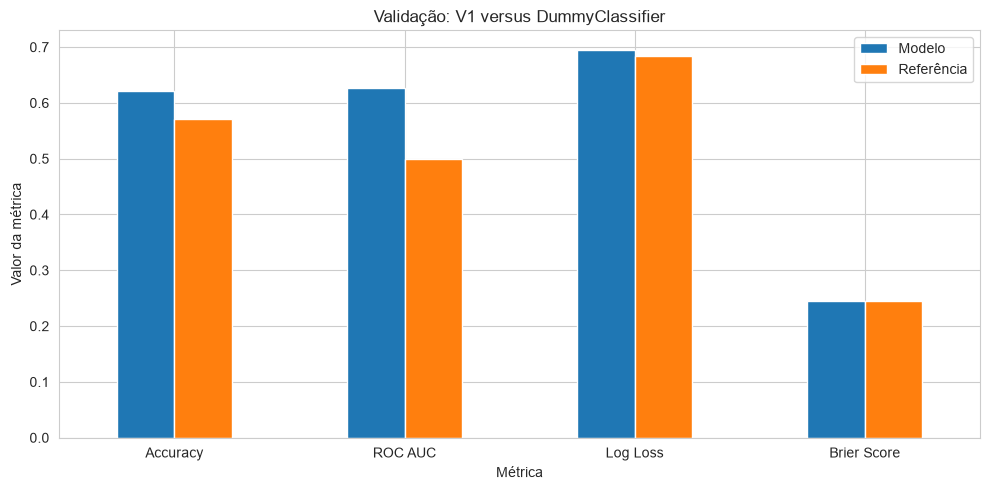

In [258]:
pred_validacao = modelo.predict(x_validacao)
prob_validacao = modelo.predict_proba(x_validacao)[:, 1]

referencia = DummyClassifier(strategy="prior")
referencia.fit(x_treino, y_treino)
pred_referencia = referencia.predict(x_validacao)
prob_referencia = referencia.predict_proba(x_validacao)[:, 1]

df_metricas = pd.DataFrame({
    "Modelo": [
        accuracy_score(y_validacao, pred_validacao),
        roc_auc_score(y_validacao, prob_validacao),
        log_loss(y_validacao, prob_validacao),
        brier_score_loss(y_validacao, prob_validacao),
    ],
    "Referência": [
        accuracy_score(y_validacao, pred_referencia),
        roc_auc_score(y_validacao, prob_referencia),
        log_loss(y_validacao, prob_referencia),
        brier_score_loss(y_validacao, prob_referencia),
    ],
}, index=["Accuracy", "ROC AUC", "Log Loss", "Brier Score"])
display(df_metricas)

# Compare as versões dentro de cada métrica; as direções e escalas diferem.
df_metricas.plot(kind="bar", figsize=(10, 5))
plt.title("Validação: V1 versus DummyClassifier")
plt.ylabel("Valor da métrica")
plt.xlabel("Métrica")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.3 Diagnóstico dos erros mais confiantes

`prob_team1` é a probabilidade da primeira equipe. `confianca` escolhe a probabilidade atribuída à classe prevista: `max(p, 1 - p)`.

A tabela mostra dez erros com maior confiança para orientar a investigação. Como ela foi selecionada justamente entre os erros, não descreve sozinha o comportamento de todos os confrontos nem prova descalibração global. A calibração precisará de uma análise própria.

In [259]:
df_diagnostico_validacao = df_validacao[
    ["match_id", "datetime", "team1", "team2"]
].copy()
df_diagnostico_validacao["real"] = np.asarray(y_validacao)
df_diagnostico_validacao["previsto"] = pred_validacao
df_diagnostico_validacao["prob_team1"] = prob_validacao
df_diagnostico_validacao["confianca"] = np.maximum(
    prob_validacao, 1 - prob_validacao
)

erros = df_diagnostico_validacao.loc[
    df_diagnostico_validacao["real"]
    != df_diagnostico_validacao["previsto"]
]
display(erros.sort_values("confianca", ascending=False).head(10))

,match_id,datetime,team1,team2,real,previsto,prob_team1,confianca
4234,7301234,2026-05-12 21:00:00,Team Vitality,BETBOOM TEAM,0,1,0.971674,0.971674
4390,7302612,2026-06-12 19:45:00,Team Vitality,9z Team,0,1,0.955186,0.955186
3776,5925555,2026-01-13 16:30:00,FaZe Clan,EYEBALLERS,0,1,0.939115,0.939115
4116,10091552,2026-04-04 19:00:00,FaZe Clan,EYEBALLERS,0,1,0.930927,0.930927
4377,7302562,2026-06-11 12:00:00,The Mongolz,BETBOOM TEAM,0,1,0.926287,0.926287
4061,6846774,2026-03-13 19:00:00,MOUZ,FUT Esports,0,1,0.913499,0.913499
4400,7302736,2026-06-14 15:00:00,MOUZ,FUT Esports,0,1,0.913036,0.913036
4129,7299258,2026-04-06 15:40:00,Inner Circle,FaZe Clan,1,0,0.091876,0.908124
4119,10091632,2026-04-05 11:00:00,FaZe Clan,Wildcard Gaming,0,1,0.905814,0.905814
4314,7301543,2026-06-02 15:50:00,Heroic,DENDELE CS,0,1,0.903525,0.903525


### 6.4 Salvamento do modelo

Salvando o estado atual do modelo para recordação do primeiro modelo construido e tambem para comparar com o resultado final depois de todo o projeto ser concluido

In [1]:
#import joblib
#from pathlib import Path

#pasta_modelos = Path("modelos")
#pasta_modelos.mkdir(exist_ok=True)

#caminho_modelo = pasta_modelos / "modelo_v1.joblib"

#joblib.dump(modelo, caminho_modelo, compress=3)

#print("Modelo salvo em:", caminho_modelo.resolve())

In [ ]:
import sys
import json
import joblib
import pandas as pd
from pathlib import Path

projeto = Path(r"C:\Users\roger.peloso\Desktop\major")
sys.path.insert(0, str(projeto / "scripts"))

from modelo_simetrico import ModeloSimetrico
from simular_singapura import snapshots, probability_matrices, monte_carlo

# Carregar a V1 e suas quatro entradas
modelo_v1 = joblib.load(projeto / "modelos/modelo_v1.joblib")
colunas_v1 = list(modelo_v1.feature_names_in_)
modelo_simulacao = ModeloSimetrico(modelo_v1)

# Carregar a configuração do Major já preparado
ponteiro = json.loads(
    (projeto / "singapura_2026/ultima_preparacao.json")
    .read_text(encoding="utf-8")
)
pasta_fontes = Path(ponteiro["pasta_fontes"])

configuracao = json.loads(
    (pasta_fontes / "config_torneio.json")
    .read_text(encoding="utf-8")
)

# Preparar os históricos e as probabilidades dos confrontos
historicos, participantes, _ = snapshots(configuracao, pasta_fontes)

chaves, matrizes, _ = probability_matrices(
    configuracao, historicos, modelo_simulacao, colunas_v1
)

# Simular o campeonato 20 mil vezes
n_simulacoes = 20_000

contagens, _, _ = monte_carlo(
    configuracao,
    chaves,
    matrizes,
    iterations=n_simulacoes,
    seed=25
)

# A coluna 5 contém a quantidade de títulos em cada simulação
resultado_v1 = pd.DataFrame({
    "chave": chaves,
    "chance_titulo_pct": 100 * contagens[:, 5] / n_simulacoes
})

colunas_fases = [
    "alcancar_etapa2_ou_superior",
    "alcancar_etapa3_ou_superior",
    "chegar_playoffs",
    "chegar_semifinal",
    "chegar_final",
    "ser_campea",
    "terceiro_lugar"
]

resultado_v1 = pd.DataFrame(
    100 * contagens / n_simulacoes,
    index=chaves,
    columns=colunas_fases
).reset_index(names="chave")

resultado_v1 = (
    resultado_v1
    .merge(
        participantes[["chave", "nome_oficial", "etapa_entrada"]],
        on="chave",
        validate="one_to_one"
    )
    .sort_values("ser_campea", ascending=False)
)

print("Todas as chances estão em porcentagem.")

display(
    resultado_v1[
        ["nome_oficial", "etapa_entrada"] + colunas_fases
    ].round(2)
)

print("Favorito da V1:", resultado_v1.iloc[0]["nome_oficial"])

Simulacoes: 5000/50000
Simulacoes: 10000/50000
Simulacoes: 15000/50000
Simulacoes: 20000/50000
Simulacoes: 25000/50000
Simulacoes: 30000/50000
Simulacoes: 35000/50000
Simulacoes: 40000/50000
Simulacoes: 45000/50000
Simulacoes: 50000/50000
Todas as chances estão em porcentagem.


,nome_oficial,etapa_entrada,alcancar_etapa2_ou_superior,alcancar_etapa3_ou_superior,chegar_playoffs,chegar_semifinal,chegar_final,ser_campea,terceiro_lugar
25,Team Vitality,3,100.00,100.00,89.48,63.52,43.22,28.07,14.40
28,Team Spirit,3,100.00,100.00,87.45,58.86,36.40,20.87,14.59
24,MOUZ,3,100.00,100.00,80.18,48.07,26.00,12.79,13.03
26,FURIA,3,100.00,100.00,71.95,36.78,16.40,6.63,10.25
21,Astralis,2,100.00,50.11,25.08,12.47,6.26,3.19,3.07
19,The One,2,100.00,49.90,24.76,12.46,6.33,3.18,3.11
22,The MongolZ,2,100.00,73.77,44.07,19.70,7.87,2.82,5.22
20,Natus Vincere,2,100.00,73.24,44.14,20.08,8.21,2.81,5.30
18,G2 Esports,2,100.00,71.83,40.37,17.21,6.58,2.26,4.48
30,Team Falcons,3,100.00,100.00,50.20,18.55,5.83,1.63,4.66


Favorito da V1: Team Vitality


<a id="integracao-hltv"></a>
## 7. Integração com o ranking histórico HLTV

O coletor esta no commit `a1102b131e4d6d2d7d10335e490aebd736248a59`, em `Desktop/hltv-scraper-api`, com ambiente próprio Python 3.11.14. O projeto do modelo continua em Python 3.14.3.

<a id="proximos-passos"></a>
### 7.1 Entregas da reconstrução

| Passo | Estado verificado |
|---|---|
| 25 | Piloto da API concluído, com resposta bruta e ambiente arquivados. |
| 26 | Equivalências corroboradas por participação; casos sem evidência permanecem ausentes. |
| 27 | Histórico arquivado e calendário conferido pelos links das publicações. |
| 28 | Ranking anterior associado, com controle de data, idade e cobertura. |
| 29 | Mapas auditados; rejeitados preservados com motivo. |
| 30 | Históricos anteriores por equipe e mapa conferidos por soma direta. |
| 31–32 | Comparações separadas de ranking e mapas, nas mesmas linhas de validação. |
| 33 | Versão fixada antes da avaliação única do teste final. |
| 34 | Simulação exploratória do PGL Major Singapore 2026 executada. |

Os resultados e suas limitações estão registrados nas próximas subseções. O roteiro não reintroduz a V2 de janela de 90 dias retirada anteriormente.

### 7.2 Passo 25 — Piloto local concluído

O clone e o commit foram conferidos. As **79 dependências** foram instaladas apenas no ambiente do coletor; `uv pip check` passou e `scrapy` foi localizado nesse mesmo ambiente.

A API foi iniciada somente em `127.0.0.1:8000`, sem debug e sem recarga automática. A consulta `/api/v1/teams/rankings/hltv/2025/december/15` retornou **HTTP 200, data 2025-12-15 e 251 equipes**. O serviço foi encerrado após a consulta.

Foram conferidos tipo do ranking, IDs, links de equipes, posições e pontos. A [página histórica da HLTV](https://www.hltv.org/ranking/teams/2025/december/15) confirmou data e primeiros colocados. Após a limpeza, são mantidos os metadados e o ranking normalizado em CSV lidos pela célula abaixo, em `dados_externos/hltv/piloto_2025-12-15_20261117T175615Z`.

**Decisão:** HTTP 200 não é o critério único de sucesso. A célula abaixo lê somente os arquivos já validados.

In [1]:
# Conferência dos arquivos já produzidos; nenhuma coleta ou instalação.
import json
from pathlib import Path
import pandas as pd

pasta_projeto = Path(r"C:\Users\roger.peloso\Desktop\major")
pasta_resultados = pasta_projeto / "dados_externos" / "reconstrucao"
relatorio_modelos = json.loads((pasta_resultados / "ultimo_experimento.json").read_text(encoding="utf-8"))
pasta_experimento = Path(relatorio_modelos["pasta_experimento"])
relatorio_simulacao = json.loads((pasta_projeto / "singapura_2026" / "ultima_simulacao.json").read_text(encoding="utf-8"))
pasta_simulacao = Path(relatorio_simulacao["pasta_simulacao"])
pasta_piloto = pasta_projeto / "dados_externos" / "hltv" / "piloto_2025-12-15_20261117T175615Z"
piloto = json.loads((pasta_piloto / "metadados.json").read_text(encoding="utf-8"))
assert piloto["status"] == "conteudo_validado"
assert piloto["data_recebida"] == "2025-12-15"
print("Piloto:", piloto["api_http_status"], "| Data:", piloto["data_recebida"], "| Equipes:", piloto["equipes"])
display(pd.read_csv(pasta_piloto / "ranking_normalizado.csv").head(3))

Piloto: 200 | Data: 2025-12-15 | Equipes: 251


,data_publicada,ranking_type,hltv_team_id,nome_hltv,posicao,pontos,url_fonte
0,2025-12-15,hltv,9565,Vitality,1,954,https://www.hltv.org/ranking/teams/2025/decemb...
1,2025-12-15,hltv,8297,FURIA,2,805,https://www.hltv.org/ranking/teams/2025/decemb...
2,2025-12-15,hltv,11283,Falcons,3,585,https://www.hltv.org/ranking/teams/2025/decemb...


### 7.3 Passo 26 — Equivalências com evidência histórica

Foram corroboradas **7,156 das 10.380 participações**, usando nome compatível e pelo menos três apelidos de jogadores em comum com a publicação anterior. A normalização remove somente diferenças cosméticas de nome; sem escalação suficiente, a associação fica pendente.

Cada equivalência vale somente para a participação conferida. Não propagamos uma identidade para todo o passado/futuro. A tabela registra ID HLTV, fonte, data da edição, jogadores em comum, validade e motivo de pendência. Os IDs de participação do CSV não são tratados como IDs HLTV.

`1win Team` e `1w Team` continuam separados na base histórica. No Major, a identidade da entrada `The One` é conferida novamente com os dados oficiais e a escalação publicada; isso não funde os dois históricos locais.

**Limite:** a escalação do CSV serve como evidência retrospectiva de identidade, não como estatística de desempenho do próprio confronto. A previsão real exige identificação disponível antes do jogo.

In [2]:
df_equivalencias_hltv = pd.read_csv(pasta_resultados / "df_equivalencias_hltv.csv")
display(df_equivalencias_hltv.groupby(["status", "motivo"], dropna=False).size().rename("participacoes").reset_index())
display(df_equivalencias_hltv.loc[df_equivalencias_hltv["status"].eq("confirmada_no_confronto"), ["match_id", "nome_local", "hltv_team_id", "data_evidencia", "jogadores_em_comum", "url_evidencia"]].head(5))

,status,motivo,participacoes
0,confirmada_no_confronto,nome_compativel_e_tres_ou_mais_jogadores_da_ed...,7156
1,pendente,escalacao_local_insuficiente,3016
2,pendente,escalacao_nao_corrobora_nome,34
3,pendente,identidade_reservada_para_investigacao,39
4,pendente,nome_sem_candidato_na_edicao,135


,match_id,nome_local,hltv_team_id,data_evidencia,jogadores_em_comum,url_evidencia
74,589049,Cloud9,5752.0,2023-10-23,4,https://www.hltv.org/ranking/teams/2023/octobe...
75,589049,Fnatic,4991.0,2023-10-23,5,https://www.hltv.org/ranking/teams/2023/octobe...
76,589047,Monte,11811.0,2023-10-23,5,https://www.hltv.org/ranking/teams/2023/octobe...
77,589047,Wildcard Gaming,12257.0,2023-10-23,4,https://www.hltv.org/ranking/teams/2023/octobe...
78,589048,Ninjas in Pyjamas,4411.0,2023-10-23,3,https://www.hltv.org/ranking/teams/2023/octobe...


### 7.4 Passo 27 — Publicações brutas arquivadas

Foram validadas **201 edições**, de **2023-01-09 a 2026-11-09**, com **49,705 registros de equipes**. São mantidos o JSON extraído e os metadados de cada edição, reutilizados pela coleta, além de uma tabela normalizada agregada. Capturas HTML, cópias normalizadas por edição e relatórios sem leitura foram removidos.

A coleta completa reutilizou diretamente o parser original do coletor, com consultas sequenciais e intervalo de três segundos, após validar a API no piloto. Treino e avaliação passam a ler o arquivo local, sem consultar o site novamente.

Duas datas previstas pela segunda-feira retornaram 404: 04/03/2024 e 01/09/2025. Os links das publicações indicaram as edições reais de **05/03/2024 e 02/09/2025**; ambas foram recuperadas. As duas consultas 404 não geraram dados de entrada. A conferência final não encontrou edição referenciada ausente dentro do período.

**Decisão:** o calendário é conferido pelas publicações reais, não presumido apenas pelo dia da semana. Pontos zero observados na fonte são válidos; ponto ausente nunca é convertido em zero.

In [3]:
df_rank_historico = pd.read_csv(pasta_resultados / "df_rank_historico.csv", parse_dates=["data_publicada"])
assert not df_rank_historico.duplicated(["ranking_type", "data_publicada", "hltv_team_id"]).any()
print("Edições:", df_rank_historico["data_publicada"].nunique(), "| Registros:", len(df_rank_historico))
display(df_rank_historico[["data_publicada", "nome_hltv", "posicao", "pontos"]].head(5))

Edições: 201 | Registros: 49705


,data_publicada,nome_hltv,posicao,pontos
0,2023-01-09,HEROIC,1,982
1,2023-01-09,G2,2,865
2,2023-01-09,Liquid,3,797
3,2023-01-09,FaZe,4,788
4,2023-01-09,Outsiders,5,736


### 7.5 Passo 28 — Ranking disponível antes do confronto

Para cada confronto, usamos a publicação global mais recente com **data estritamente anterior ao dia do jogo**, com idade máxima de **14 dias**. Uma equipe ausente dessa edição fica sem ranking; não carregamos uma posição antiga nem inventamos posição zero.

O primeiro atributo experimental é `dif_pontos_hltv = pontos_team1 - pontos_team2`. A diferença de posição também foi arquivada, mas não entra no primeiro experimento para evitar acrescentar dois sinais relacionados ao mesmo tempo.

Foram preservados os **5.190 confrontos**, seus IDs e os cortes de **3.775/642/773**. Ausência de identidade ou de ranking permanece explícita, e o pipeline aprende sua imputação somente no treino. A tabela de cobertura mostra a queda de cobertura no teste.

In [4]:
df_cobertura_ranking = pd.DataFrame(relatorio_modelos["cobertura_rankings"])
display(df_cobertura_ranking)
df_base_experimentos = pd.read_csv(pasta_experimento / "base_experimentos.csv", parse_dates=["datetime"])
assert len(df_base_experimentos) == 5190
assert df_base_experimentos["match_id"].is_unique
display(df_base_experimentos[["match_id", "datetime", "team1", "team2", "dif_pontos_hltv", "dif_posicao_hltv"]].head(5))

,conjunto,linhas,ranking_dois_lados,percentual_ranking_dois_lados
0,treino,3775,2462,65.218543
1,validacao,642,551,85.825545
2,teste,773,433,56.015524


,match_id,datetime,team1,team2,dif_pontos_hltv,dif_posicao_hltv
0,10065881,2023-01-10 09:30:00,my life be like,vagrants,NaN,NaN
1,10064067,2023-10-16 04:30:00,VERTEX,MOUZ,NaN,NaN
2,10064066,2023-10-16 04:30:00,Natus Vincere,Apeks,NaN,NaN
3,10064064,2023-10-16 05:30:00,Team Vitality,BetBoom Team,NaN,NaN
4,10064065,2023-10-16 05:40:00,FaZe Clan,GamerLegion,NaN,NaN


<a id="historico-mapas"></a>
## 8. Mapas e históricos anteriores ao confronto

### 8.1 Passo 29 — Base de mapas auditada

Das **7,850 linhas** com `is_total = False`, **7,806** têm nome e placares utilizáveis; **44** foram separados com motivo. Não há duplicatas por `match_id + game_id` nem por `match_id + map_name` entre os mapas aceitos.

O vencedor do mapa vem dos placares de rounds, sem sobrescrever o vencedor original da série. Totais não entram como mapas adicionais. A cobertura dos mapas é a da amostra disponível, não a totalidade de partidas reais das equipes.

In [5]:
df_mapas = pd.read_csv(pasta_resultados / "df_mapas.csv", parse_dates=["datetime"])
df_mapas_rejeitados = pd.read_csv(pasta_resultados / "mapas_rejeitados.csv")
assert not df_mapas.duplicated(["match_id", "game_id"]).any()
assert not df_mapas.duplicated(["match_id", "map_name"]).any()
print("Mapas utilizáveis:", len(df_mapas), "| Rejeitados:", len(df_mapas_rejeitados))
display(df_mapas["map_name"].value_counts().rename("mapas"))
display(df_mapas_rejeitados[["match_id", "map_name", "score1_game", "score2_game", "motivo_rejeicao"]].head(5))

Mapas utilizáveis: 7806 | Rejeitados: 44


map_name
Mirage      1307
Ancient     1271
Nuke        1173
Inferno     1099
Dust2       1094
Anubis       822
Overpass     382
Vertigo      303
Train        222
Cache        133
Name: mapas, dtype: int64

,match_id,map_name,score1_game,score2_game,motivo_rejeicao
0,7311740,NaN,9.0,13.0,sem_nome;
1,7311740,NaN,13.0,11.0,sem_nome;
2,7306265,NaN,13.0,9.0,sem_nome;
3,7306265,NaN,13.0,8.0,sem_nome;
4,7306273,NaN,14.0,16.0,sem_nome;


### 8.2 Passo 30 — Perfil anterior por equipe e mapa

Foram construídos **103,800 perfis**: duas perspectivas por confronto para os dez mapas observados na base. Cada perfil registra jogos, vitórias, taxa e data do último mapa **estritamente anterior ao horário do confronto**. Blocos no mesmo horário não entram no próprio histórico.

**Sem mapas anteriores:** contagens zero e taxa ausente. **Identidade desconhecida na previsão:** contagens e taxas ausentes, pois não significa histórico observado de zero jogos.

As entradas do experimento usam apenas os **nove mapas encontrados no treino**, com diferenças de jogos e taxas por mapa. `Cache` apareceu somente após o treino: permanece na auditoria, mas não foi acrescentado ao vocabulário do modelo.

Esses atributos descrevem desempenho histórico em mapas fixados no treino; não declaram o pool ativo da época e não usam os mapas que acabaram sendo escolhidos no confronto. Um modelo após o veto ou uma simulação de vetos exigiria outra definição. **Doze exemplos** foram conferidos por soma direta dos jogos anteriores.

In [6]:
df_historico_mapas = pd.read_csv(pasta_resultados / "df_historico_mapas.csv", parse_dates=["datetime", "data_ultimo_mapa"])
assert (df_historico_mapas["data_ultimo_mapa"].isna() | df_historico_mapas["data_ultimo_mapa"].lt(df_historico_mapas["datetime"])).all()
exemplo_mapas = df_historico_mapas.loc[df_historico_mapas["equipe"].eq("Team Vitality") & df_historico_mapas["datetime"].lt("2026-01-01")]
display(exemplo_mapas.loc[exemplo_mapas["datetime"].eq(exemplo_mapas["datetime"].max()), ["match_id", "equipe", "datetime", "map_name", "jogos_anteriores", "vitorias_anteriores", "taxa_vitorias_anteriores"]])
conferencia_mapas = pd.read_json(pasta_resultados / "conferencia_manual_mapas.json")
assert conferencia_mapas["conferido"].all()
print("Perfis:", len(df_historico_mapas), "| Exemplos conferidos por soma direta:", len(conferencia_mapas))

,match_id,equipe,datetime,map_name,jogos_anteriores,vitorias_anteriores,taxa_vitorias_anteriores
7548,5796473,Team Vitality,2025-12-14 20:00:00,Ancient,1,0,0.000000
17928,5796473,Team Vitality,2025-12-14 20:00:00,Anubis,36,21,0.583333
28308,5796473,Team Vitality,2025-12-14 20:00:00,Cache,0,0,NaN
38688,5796473,Team Vitality,2025-12-14 20:00:00,Dust2,55,44,0.800000
49068,5796473,Team Vitality,2025-12-14 20:00:00,Inferno,73,53,0.726027
59448,5796473,Team Vitality,2025-12-14 20:00:00,Mirage,64,44,0.687500
69828,5796473,Team Vitality,2025-12-14 20:00:00,Nuke,67,49,0.731343
80208,5796473,Team Vitality,2025-12-14 20:00:00,Overpass,12,7,0.583333
90588,5796473,Team Vitality,2025-12-14 20:00:00,Train,21,14,0.666667
100968,5796473,Team Vitality,2025-12-14 20:00:00,Vertigo,14,10,0.714286


Perfis: 103800 | Exemplos conferidos por soma direta: 12


<a id="experimentos-major"></a>
## 9. Experimentos, teste final e Major de Singapura

### 9.1 Passo 31 — Contribuição do ranking

Mantivemos os mesmos cortes, algoritmo e quatro entradas da V1, acrescentando somente a diferença de pontos. Todas as versões usam as mesmas linhas de validação, inclusive quando o ranking está ausente.

Na comparação sem simetrização, o ranking reduziu o Log Loss de **0,695017 para 0,670888**, mas a acurácia passou de **0,621495 para 0,616822**. O ganho é na qualidade das probabilidades nessa validação; não é melhoria de todas as métricas.

In [7]:
df_metricas_reconstrucao = pd.DataFrame(relatorio_modelos["metricas_validacao"])
display(df_metricas_reconstrucao.loc[df_metricas_reconstrucao["modelo"].isin(["V1", "V1 + ranking", "Referencia"]), ["modelo", "accuracy", "roc_auc", "log_loss", "brier"]])

,modelo,accuracy,roc_auc,log_loss,brier
0,V1,0.621495,0.626138,0.695017,0.244073
1,V1 + ranking,0.616822,0.643022,0.670888,0.236075
4,Referencia,0.571651,0.500000,0.683427,0.245153


### 9.2 Passo 32 — Mapas e combinação de atributos

Foram comparados os grupos V1, V1 + ranking, V1 + mapas e V1 + ranking + mapas. As versões com mapas acrescentam 18 diferenças referentes ao vocabulário aprendido no treino.

As variáveis de mapas não melhoraram o Log Loss frente à versão com ranking nessa validação. Por isso, **não entraram na versão escolhida**. A base e as métricas lidas pelo notebook foram mantidas; modelos intermediários sem leitura foram removidos.

Para usar o modelo num torneio, também verificamos a ordem das equipes. A probabilidade simétrica é `p_sim(A, B) = (p_modelo(A, B) + 1 - p_modelo(B, A)) / 2`: invertem-se todas as diferenças, mantendo `bestOf`. Isso garante probabilidades complementares ao trocar as equipes. Essa regra foi comparada na validação **antes de olhar o teste**; não foi aplicada depois como ajuste oportunista.

In [8]:
display(df_metricas_reconstrucao[["modelo", "entradas", "linhas_validacao", "accuracy", "roc_auc", "log_loss", "brier"]])
print("Versão fixada na validação:", relatorio_modelos["melhor_log_loss_validacao"])

,modelo,entradas,linhas_validacao,accuracy,roc_auc,log_loss,brier
0,V1,4,642,0.621495,0.626138,0.695017,0.244073
1,V1 + ranking,5,642,0.616822,0.643022,0.670888,0.236075
2,V1 + mapas,22,642,0.630841,0.644801,0.704215,0.243892
3,V1 + ranking + mapas,23,642,0.627726,0.645643,0.681872,0.239024
4,Referencia,0,642,0.571651,0.500000,0.683427,0.245153
5,V1 (simetrico),4,642,0.618380,0.626222,0.693917,0.244545
6,V1 + ranking (simetrico),5,642,0.613707,0.643309,0.669248,0.235692
7,V1 + mapas (simetrico),22,642,0.637072,0.644597,0.704966,0.244457
8,V1 + ranking + mapas (simetrico),23,642,0.623053,0.647203,0.680823,0.238625
9,Referencia (simetrico),4,642,0.428349,0.500000,0.693147,0.250000


Versão fixada na validação: V1 + ranking (simetrico)


### 9.3 Passo 33 — Versão fixada e teste final executado

**Regra registrada antes do teste:** entre versões com probabilidades simétricas, escolher o menor Log Loss na validação, com Brier como desempate. A referência neutra simétrica também participou. Versões originais foram mantidas como comparação.

Foi escolhida **V1 + ranking (simetrico)**, com cinco entradas: as quatro da V1 e `dif_pontos_hltv`. Os parâmetros continuam aprendidos somente no treino; não houve retreino após a seleção.

O arquivo `selecao_antes_do_teste.json` foi salvo antes da avaliação dos **773 confrontos** do teste. A escolha não foi alterada ao ver o resultado. O teste já foi utilizado; ele deixa de ser um conjunto inédito para futuras escolhas.

**Leitura crítica:** o Log Loss final de **0,686418** ficou muito próximo dos **0,686521** da referência. A acurácia da versão escolhida foi **57,57%**, contra **63,52%** da V1 original. A V1 também teve Brier ligeiramente melhor no teste. O ranking melhorou a ordenação frente à referência, mas isso não demonstra um modelo forte ou probabilidades bem calibradas para o Major.

O novo modelo e sua definição ficam em `experimentos/reconstrucao_20261117T181218Z`. O `modelo_v1.joblib` permanece intacto. Para carregar a versão simétrica, disponibilize `scripts/modelo_simetrico.py` no caminho de importação junto ao ambiente compatível.

In [9]:
selecao_modelo = json.loads((pasta_experimento / "selecao_antes_do_teste.json").read_text(encoding="utf-8"))
assert selecao_modelo["teste_avaliado_neste_momento"] is False
print("Seleção registrada em:", selecao_modelo["fixado_em_utc"])
print("Entradas:", selecao_modelo["entradas"])
print("Modelo salvo:", pasta_experimento / "modelo_selecionado.joblib")
df_teste_final = pd.DataFrame(relatorio_modelos["metricas_teste_final"])
display(df_teste_final)
# Apenas leitura do resultado final já arquivado; não refaz escolhas com o teste.

Seleção registrada em: 2026-11-17T18:12:18.469968+00:00
Entradas: ['dif_jogos_anteriores', 'dif_vitorias_anteriores', 'dif_taxa_vitorias_anteriores', 'bestOf', 'dif_pontos_hltv']
Modelo salvo: C:\Users\roger.peloso\Desktop\major\experimentos\reconstrucao_20261117T181218Z\modelo_selecionado.joblib


,modelo,linhas_teste,accuracy,roc_auc,log_loss,brier
0,V1 + ranking (simetrico),773,0.575679,0.635046,0.686418,0.241700
1,V1,773,0.635188,0.645965,0.693055,0.241089
2,Referencia,773,0.557568,0.500000,0.686521,0.246694


### 9.4 Passo 34 — PGL Major Singapore 2026

Foi preparada uma previsão em **17/11/2026**, antes do evento, com resultados locais até **14/11** e ranking publicado em **16/11**. A [página oficial da PGL](https://www.pglesports.com/cs2/pgl-major-singapore-2026/) forneceu os participantes, escalações, sementes e regras preservados na configuração usada pela simulação. Capturas HTML/JavaScript sem leitura foram removidas.

O motor usa as três etapas suíças e os playoffs: três vitórias classificam, três derrotas eliminam; etapas 1 e 2 têm MD3 em avanço/eliminação; etapa 3 é toda MD3. Pareamentos respeitam campanha, Buchholz, semente e ausência de revanche na mesma etapa, incluindo a prioridade dos grupos de seis. Os classificados entram na etapa seguinte na ordem final anterior. Quartas, semis e terceiro lugar são MD3; a final é MD5.

Foram executadas **20,000 simulações**, com semente 25. As entradas ficam congeladas: resultados simulados não atualizam os históricos. A previsão é da série, sem usar um veto futuro. As probabilidades por confronto são diferentes das probabilidades de o confronto acontecer.

**Cobertura:** ranking corroborado para **32/32** equipes; identidade local corroborada para **22/32**. Nas demais, as estatísticas locais ficam ausentes e passam pela imputação aprendida no treino. Não são inventadas partidas nem zero jogos.

As tabelas abaixo mostram chances por fase, primeira rodada e as equipes com histórico local não corroborado. O intervalo de Monte Carlo mede somente o erro das simulações; a incerteza do modelo, das escalações e da cobertura é maior e não está contida nele. Estes resultados são **exploratórios**, sobretudo diante do pequeno ganho no teste.

In [10]:
df_chances_major = pd.read_csv(pasta_simulacao / "chances_por_equipe.csv")
df_participantes_major = pd.read_csv(pasta_simulacao / "participantes_e_cobertura.csv")
nomes_major = dict(zip(df_participantes_major["chave"], df_participantes_major["nome_oficial"]))
colunas_chances = ["chegar_playoffs", "chegar_semifinal", "chegar_final", "ser_campea"]
tabela_chances = df_chances_major[["nome_oficial", "etapa_entrada"] + colunas_chances].copy()
tabela_chances[colunas_chances] = (100 * tabela_chances[colunas_chances]).round(2)
print("Chances em %; resultados exploratórios de", relatorio_simulacao["simulacoes"], "simulações.")
display(tabela_chances)
df_primeira_rodada = pd.read_csv(pasta_simulacao / "primeira_rodada.csv")
df_primeira_rodada[["equipe_a", "equipe_b"]] = df_primeira_rodada[["equipe_a", "equipe_b"]].replace(nomes_major)
display(df_primeira_rodada)
display(df_participantes_major.loc[df_participantes_major["nome_local"].isna(), ["nome_oficial", "status_local", "status_ranking"]])
assert abs(df_chances_major["ser_campea"].sum() - 1) < 1e-12
assert abs(df_chances_major["chegar_playoffs"].sum() - 8) < 1e-12
print("Todos os resultados:", pasta_simulacao)

Chances em %; resultados exploratórios de 20000 simulações.


,nome_oficial,etapa_entrada,chegar_playoffs,chegar_semifinal,chegar_final,ser_campea
0,FURIA,3,96.28,74.29,51.52,33.17
1,MOUZ,3,94.21,67.72,41.87,23.91
2,Team Spirit,3,92.06,62.72,36.12,18.62
3,Team Vitality,3,89.27,57.04,29.80,13.76
4,Team Falcons,3,66.42,27.21,9.43,2.94
5,Natus Vincere,2,45.80,17.82,6.16,1.77
6,Aurora Gaming,3,58.90,21.20,6.20,1.58
7,The MongolZ,2,40.46,15.14,4.52,1.24
8,G2 Esports,2,37.60,13.40,4.14,1.00
9,The One,2,15.52,5.16,1.49,0.38


,equipe_a,equipe_b,bestOf,prob_vitoria_a,prob_vitoria_b
0,Ninjas in Pyjamas,M80,1,0.544008,0.455992
1,PVISION,DENDELE,1,0.560588,0.439412
2,HEROIC,Imperial Esports,1,0.521297,0.478703
3,FaZe Clan,Wildcard,1,0.525202,0.474798
4,Team Liquid,GOSH,1,0.542949,0.457051
5,Eternal Fire,FlyQuest,1,0.526504,0.473496
6,100 Thieves,Chinggis Warriors,1,0.517389,0.482611
7,9z Globant,Lynn Vision Gaming,1,0.525636,0.474364


,nome_oficial,status_local,status_ranking
6,100 Thieves,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
9,DENDELE,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
10,Imperial Esports,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
11,Wildcard,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
12,GOSH,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
13,FlyQuest,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
14,Chinggis Warriors,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
15,Lynn Vision Gaming,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
19,The One,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao
21,Astralis,sem_identidade_local_corroborada,corroborado_por_nome_e_escalacao


Todos os resultados: C:\Users\roger.peloso\Desktop\major\singapura_2026\simulacao_20261117T181507Z


<a id="decisoes"></a>
## 10. Registro de decisões e limites

| Decisão adotada | Por que foi adequada | Limite ou revisão futura |
|---|---|---|
| Uma linha por série na V1 | A previsão desejada é o vencedor do confronto completo. | Desempenho por mapa precisa de uma tabela auxiliar própria. |
| Remover somente duas duplicatas verificadas | Evita descartar dados válidos por uma regra ampla baseada no nome do campeonato. | Novas cargas precisam passar novamente pela auditoria de unicidade. |
| Reconstruir o alvo sem sobrescrever `team1_win` | Torna explícita a regra do vencedor e conserva a fonte para investigar erros. | Placares também podem ter erros; não foram todos verificados externamente. |
| Deixar empate e placar incompleto sem alvo | Impede inventar uma derrota ou vitória. | Casos 7298927 e 10095505 aguardam evidência suficiente. |
| Usar nomes exatos como chave provisória | Os IDs do CSV não acompanham a organização entre confrontos. | Equivalências com HLTV precisam ser verificadas, inclusive ao longo do tempo. |
| Manter `1win Team` e `1w Team` separados | A continuidade não foi confirmada. | Não é uma afirmação definitiva sobre a identidade das organizações. |
| Excluir o bloco de horário atual do histórico | Impede aproveitar resultados de jogos registrados no mesmo horário. | Verificar fuso e sobreposição entre início e término em aplicação real. |
| Conservar taxa ausente sem jogos anteriores | Separa falta de informação de desempenho observado de 0%. | O pipeline imputa o valor com base no treino. |
| Validar as junções com `many_to_one` | Ajuda a detectar multiplicação de confrontos. | Também conferir quantidade de linhas, IDs e cobertura após cada nova fonte. |
| Separar os conjuntos por data | Respeita a ordem temporal da aplicação pretendida. | Validação repetida pode favorecer escolhas específicas desse período. |
| Aprender imputação, escala e regressão no treino | Evita aprender transformações com validação ou teste. | Toda versão nova deverá manter esse procedimento. |
| Comparar com DummyClassifier e avaliar probabilidades | Acurácia isolada não basta para uma futura simulação de torneio. | É preciso avaliar calibração, qualidade por período e teste final. |

### O que ainda não foi demonstrado

- A V1 original considera somente histórico de séries e formato. A evolução acrescentou ranking e testou históricos de mapas, conforme as seções 7–9; isso não incorpora diretamente força de cada jogador ou mudanças de escalação.
- Os nomes podem agrupar fases de escalação muito diferentes. Um ID estável da organização também não resolve sozinho mudanças de elenco.
- A base tier 1 pode conter somente parte do histórico real de cada equipe. Portanto, as taxas calculadas são **taxas dentro da amostra disponível**, não necessariamente as taxas completas da HLTV.
- Uma taxa histórica de 90% não é, por si só, 90% de chance de vencer qualquer adversário.
- Um pequeno ganho na validação não garante ganho em um novo período. A ausência de ganho também não prova que o atributo seja inútil em qualquer configuração.
- A V2 removida não serve como versão ativa. A reconstrução foi comparada com a V1 preservada.

### Decisões da evolução executada

- A simulação usa probabilidades simétricas e a versão escolhida somente na validação.
- O teste final já foi usado; novas escolhas precisam de nova evidência fora dessa amostra.
- Mapas não entraram na versão selecionada, pois não melhoraram o Log Loss de validação frente ao ranking.
- Identidades e estatísticas ausentes permanecem explícitas. Nenhuma ausência de correspondência vira zero jogos ou posição zero.
- O Major usa dados congelados antes do evento, participantes e regras oficiais arquivados.
- A vantagem mínima em Log Loss no teste e a cobertura local parcial limitam a confiança nas chances de campeão.